# 07 ผลการทดลองและ Evaluation Metrics ย้อนหลังปี 2024/2025 ของโมเดลที่ล็อกไว้จาก 06

> **โหมดวิจัยย้อนหลังแบบมีเงื่อนไขเท่านั้น** — `research_mode = retrospective_conditional_research`, `production_enabled = False`, ความพร้อมของโมเดลจริงยัง **BLOCKED**
> - ให้คะแนนเฉพาะเซลล์ จังหวัด × วัน ที่ `training_eligible` ใน `validation` (2024) และ `reused_test_2025` เท่านั้น ตัวกรองนี้รู้หลังเห็นปัญหาคุณภาพข้อมูล จึงมี **selection bias** คะแนนไม่ใช่ความแม่นยำทั้งปี ทั้งประเทศ หรือรายสายทาง
> - ปี 2024 ไม่มีเซลล์ eligible ในบางเดือน (รวมไตรมาส 4) ตารางจึงแสดง *ไม่มี support / คะแนน null* ไม่ใช่ error เป็นศูนย์; ปี 2025 เคยถูกดูมาแล้ว — **ไม่มี test อิสระที่ยังไม่เคยเห็น**
> - ผลปีหลังเป็น **การวินิจฉัยเท่านั้น**: ไม่ refit ไม่ tune ไม่ calibrate และ **ไม่เปลี่ยน** selected candidate / strongest baseline / recommended reference ที่ล็อกจาก OOF ใน 06 แม้อันดับปีหลังจะต่างไป
> - ไม่ใช้ป้ายกำกับปี 2026 (`diagnostic_2026` ไม่มี ACC_CODE) และไม่ใช่ความเสี่ยงอุบัติเหตุรายบุคคล

**เป้าหมาย:** วัดผลโมเดลที่ฝึกและล็อกแล้วใน 06 ทั้ง 11 วิธี (Baseline 4 + Poisson 3 + Random Forest 2 + HGB 2) บนเซลล์ eligible ปี 2024 และ 2025 ชุดเดียวกันทุกวิธี แล้วสรุปเป็นตารางผลหลัก (ตัวดีที่สุดของแต่ละตระกูลจาก OOF, Baseline ที่แข็งที่สุด, Zero baseline แยกแถว) ตารางทุก configuration และตาราง coverage ครบทุกเดือน

**อินพุต (อ่านอย่างเดียว ตรวจ SHA256 ก่อนใช้):**
- ข้อมูลใต้ `ROADAWARE_DATA_ROOT` (ค่าเริ่มต้น `backend/`): `data/processed/province_day_panel.csv` + manifest สามชั้น + รายงาน leakage/readiness (ตรวจซ้ำด้วย `verify_data_foundation` ของ 06)
- ผลของ 06 ใต้ `ROADAWARE_OUTPUT_DIR` (ค่าเริ่มต้น `backend/`): `reports/models/experiment_manifest.json` และ `model_artifact_manifest.json` (ต้อง `status == ok`), `selection_lock.json`, `oof_metrics.csv`, `support_by_split_month.csv`, `fit_log_full_train.csv` และ bundle `data/model/bundles/*.joblib`
- เซลล์ `# FUNCTIONS` ของ 06 — ดึงออกมาแบบระบุชัด และ exec **เฉพาะเมื่อ** SHA256 ของ source ตรงกับที่ manifest ของ 06 บันทึกไว้ (ไม่พึ่ง kernel เดิม รันจาก kernel ใหม่ได้)

**การแปลง/ขั้นตอน:**
1. ตรวจ config = โปรโตคอลที่ล็อก, ตรวจ data foundation, hash ของ protocol/config/notebook 06 (semantic + FUNCTIONS) และ data contract ต้องตรงกับ manifest ของ 06
2. ตรวจ SHA256 ของทุกไฟล์และทุก bundle ที่ 06 ระบุ **ก่อน** unpickle; ตรวจ `selection_lock.json` (ไบต์ไฟล์, `decision_sha256`, `choice_sha256`) และความสอดคล้องกับ manifest
3. โหลด bundle (ตรวจ hash ซ้ำทันทีก่อนโหลด) และตรวจ metadata ตรงกับ spec ที่ล็อก; ทำนาย Train เพื่อยืนยันว่าเป็นโมเดลเดียวกับ 06 (บันทึกคะแนน in-sample แยกไฟล์ ไม่ปนกับ OOF หรือปีหลัง)
4. เลือกเซลล์ eligible ของ validation/reused_test_2025 (parse boolean แบบเข้มงวด, ไม่มีปี 2026, key ไม่ซ้ำ) และทำนายด้วยทุก bundle บน key ชุดเดียวกัน
5. บันทึก prediction รายเซลล์ไว้ที่ `data/model/diagnostic_predictions.csv` (ไม่อยู่ใน git) อ่านกลับ แล้วคำนวณ metric **จากไฟล์ที่บันทึก** ด้วย `regression_metrics` ของ 06
6. คำนวณ metric ซ้ำแบบอิสระ (scikit-learn + ผลรวม numpy) และ assert ว่าตรงกัน; ตาราง coverage ครบ 60 เดือนตรวจเทียบกับ `support_by_split_month.csv` ของ 06
7. ตรวจ lock และทุกไฟล์ของ 06 อีกครั้งหลังให้คะแนน แล้วจึงเขียน `diagnostic_manifest.json` สถานะ `ok`

**Metric:** primary = mean Poisson deviance (floor ค่าทำนายที่ 1e-9 เฉพาะตอนคำนวณ deviance และนับจำนวนแถวที่ถูก floor); Zero baseline มี deviance = null (ศูนย์อยู่นอกโดเมน); MAE/RMSE/bias/WAPE/ผลรวมใช้ค่าทำนายดิบ; WAPE = null เมื่อผลรวมจริงเป็น 0; กลุ่มที่ไม่มีเซลล์ eligible ได้คะแนนและผลรวม null

**เอาต์พุต:** `reports/models/diagnostics/` (CSV/JSON/PNG ขนาดเล็ก ไม่มีข้อมูลรายแถว) และ `data/model/diagnostic_predictions.csv` (รายแถว ไม่อยู่ใน git) พร้อม `diagnostic_manifest.json` ที่มี hash, เวอร์ชันแพ็กเกจ, สถานะ และสัญญาสำหรับ Notebook 08

**ข้อจำกัด:** เซลล์ eligible เท่านั้น (selection bias); ปี 2024 ขาดหลายเดือน; ปี 2025 เคยถูกดู; ไม่มี lag/สภาพอากาศ/วันหยุด/การจราจร; การจัดอันดับปีหลังไม่ใช่เกณฑ์เลือกโมเดล; ไม่มีการอ้างความแม่นยำรายสายทางหรือความน่าจะเป็นรายบุคคล

**ผลลัพธ์จริง:** ตาราง/กราฟด้านล่างมาจากการรันจริงเท่านั้น ถ้าไม่มี output แปลว่ายังไม่ได้รัน

In [1]:
# FUNCTIONS (notebook 07) - later-year diagnostics of the FROZEN notebook-06 models; tests execute this cell directly
# These helpers call notebook-06 helpers by name (regression_metrics, predict_bundle, sha256_file, canonical_json, ...):
# the verified 06 '# FUNCTIONS' cell is executed into the same namespace by load_verified_06_functions before any of
# them is called. Nothing here rebinds a 06 name (checked by backend/tests/test_model_notebooks.py). No fitting,
# tuning, calibration or selection happens in 07.
import hashlib, json, math, os, time
from pathlib import Path
import numpy as np, pandas as pd

PRODUCER_06 = '06_baseline_candidate_models'
PRODUCER_07 = '07_evaluation_experiment_results'
DIAG_FORMAT = 'roadaware_later_year_diagnostics_v1'
DIAGNOSTIC_SPLITS = ['validation', 'reused_test_2025']
SCOPE_BY_SPLIT = {'validation': 'diagnostic_validation_2024', 'reused_test_2025': 'diagnostic_reused_test_2025'}
POOLED_SCOPE = 'diagnostic_pooled_2024_2025'
DIAG_SCOPES = [SCOPE_BY_SPLIT[s] for s in DIAGNOSTIC_SPLITS] + [POOLED_SCOPE]
TRAIN_IN_SAMPLE_SCOPE = 'train_in_sample_full_fit'
# Source hashes that must equal the 06 manifests exactly. runner_sha256 is deliberately absent: the runner gains stage
# support for 07/08, so its bytes are recorded as provenance, never required to equal the 06-time runner.
STRICT_SOURCE_KEYS = ['protocol_sha256', 'experiment_config_sha256', 'data_pipeline_config_sha256',
                      'notebook_semantic_sha256', 'functions_cell_sha256']
SUPPORT_KEYS = ['support_status', 'n_distinct_dates', 'n_months_with_support', 'n_provinces', 'first_date', 'last_date']
METRIC_RECOMPUTE_TOL = 1e-10
DIAG_CAVEATS = [
    'Later-year scores are retrospective diagnostics of FROZEN models; they never change the OOF-locked selected candidate, strongest baseline or recommended reference.',
    'Only training_eligible cells are scored (selection-biased); validation 2024 lacks eligible cells in several months including Oct-Dec, so 2024 scores are not full-year.',
    'reused_test_2025 was inspected before; neither 2024 nor 2025 is an independent untouched test.',
    'Province-day recorded counts on the MOT road network: not whole-country accuracy, not route-level, not a personal crash probability.',
    'No 2026 labels are used (diagnostic_2026 has no ACC_CODE).',
    'No refit, tuning or calibration happens in 07.',
]

# ---------------------------------------------------------------- bootstrap: backend location and verified 06 helpers
def locate_backend_07(start=None):
    """Backend folder from ROADAWARE_BACKEND_ROOT or by walking up from start/cwd (repository root or backend/notebooks)."""
    env = os.environ.get('ROADAWARE_BACKEND_ROOT')
    if env:
        return Path(env).resolve()
    here = Path(start or Path.cwd()).resolve()
    for c in [here, *here.parents]:
        for b in (c / 'backend', c):
            if (b / 'notebooks' / (PRODUCER_06 + '.ipynb')).is_file() and (b / 'config').is_dir():
                return b
    raise FileNotFoundError('backend/notebooks/' + PRODUCER_06 + '.ipynb not found from ' + str(here))

def extract_verified_functions_source(nb_path, expected_sha256):
    """The single '# FUNCTIONS' code cell of a notebook, returned only if sha256(utf-8 source) == expected_sha256."""
    nb = json.loads(Path(nb_path).read_text('utf-8'))
    srcs = [''.join(c['source']) if isinstance(c['source'], list) else c['source'] for c in nb['cells'] if c['cell_type'] == 'code']
    hits = [s for s in srcs if s.lstrip().startswith('# FUNCTIONS')]
    if len(hits) != 1:
        raise ValueError(str(nb_path) + ': expected exactly one # FUNCTIONS cell, found %d' % len(hits))
    got = hashlib.sha256(hits[0].encode('utf-8')).hexdigest()
    if not expected_sha256 or got != expected_sha256:
        raise RuntimeError('FUNCTIONS cell of ' + str(nb_path) + ' has sha256 ' + got + ' but the manifest expects '
                           + str(expected_sha256) + '; refusing to execute it')
    return hits[0]

def load_verified_06_functions(nb06_path, expected_sha256, namespace):
    """Explicit, documented reuse of the 06 helpers: exec the verified 06 FUNCTIONS source into namespace."""
    src = extract_verified_functions_source(nb06_path, expected_sha256)
    exec(compile(src, '06:FUNCTIONS', 'exec'), namespace)
    return expected_sha256

def expected_06_functions_sha(exp_man, art_man, art_man_bytes):
    """06 FUNCTIONS hash to trust, cross-checked across both status-ok 06 manifests BEFORE any 06 code runs."""
    for name, m in (('experiment_manifest', exp_man), ('model_artifact_manifest', art_man)):
        if m.get('producer') != PRODUCER_06 or m.get('status') != 'ok':
            raise RuntimeError(name + ': not a status-ok notebook-06 manifest (status %r); run 06 first' % m.get('status'))
    if exp_man.get('model_artifact_manifest_sha256') != hashlib.sha256(art_man_bytes).hexdigest():
        raise RuntimeError('model_artifact_manifest.json bytes differ from the sha256 recorded in experiment_manifest.json')
    a = (exp_man.get('source') or {}).get('functions_cell_sha256')
    b = (art_man.get('source') or {}).get('functions_cell_sha256')
    if not a or a != b:
        raise RuntimeError('the two 06 manifests disagree on functions_cell_sha256')
    return a

# ---------------------------------------------------------------- upstream (notebook 06) verification
def upstream_violations(exp_man, art_man, art_man_file_sha, lock_file_sha, source_now, contract_now, spec_ids,
                        lock_rel='reports/models/selection_lock.json'):
    """Every reason the notebook-06 outputs may not be trusted by 07 (empty list = trusted)."""
    v = []
    for name, m in (('experiment_manifest', exp_man), ('model_artifact_manifest', art_man)):
        if m.get('producer') != PRODUCER_06:
            v.append(name + ': producer is not ' + PRODUCER_06)
        if m.get('status') != 'ok':
            v.append(name + ': status %r is not ok (incomplete or failed 06 run)' % m.get('status'))
        src = m.get('source') or {}
        v += [name + ': source.' + k + ' differs from the current file' for k in STRICT_SOURCE_KEYS if src.get(k) != source_now.get(k)]
        if canonical_json(to_jsonable(m.get('contract'))) != canonical_json(to_jsonable(contract_now)):
            v.append(name + ': data/config contract differs from the verified inputs')
    if exp_man.get('model_artifact_manifest_sha256') != art_man_file_sha:
        v.append('model_artifact_manifest.json bytes differ from the sha256 recorded in experiment_manifest')
    if exp_man.get('later_years_scored_in_06') is not False:
        v.append('experiment_manifest does not state later_years_scored_in_06 = false')
    if exp_man.get('production_enabled') is not False:
        v.append('experiment_manifest does not state production_enabled = false')
    sel = exp_man.get('selection') or {}
    if (sel.get('decision_sha256'), sel.get('choice_sha256')) != (art_man.get('selection_lock_decision_sha256'), art_man.get('selection_lock_choice_sha256')):
        v.append('selection lock hashes differ between the two manifests')
    listed = {f.get('path'): f.get('sha256') for f in art_man.get('files', [])}
    if exp_man.get('selection_lock_file_sha256') != lock_file_sha or listed.get(lock_rel) != lock_file_sha:
        v.append('selection_lock.json bytes differ from the sha256 recorded by 06')
    if exp_man.get('oof_predictions_sha256') != art_man.get('oof_predictions_sha256'):
        v.append('oof_predictions sha256 differs between the two manifests')
    bundles = {}
    for b in art_man.get('bundles', []):
        if b.get('spec_id') in bundles:
            v.append('duplicate bundle entry ' + str(b.get('spec_id')))
        bundles[b.get('spec_id')] = b
    if sorted(map(str, bundles)) != sorted(map(str, spec_ids)):
        v.append('bundle spec ids differ from the frozen config spec ids')
    for sid in sorted(set(bundles) & set(spec_ids)):
        b = bundles[sid]
        if b.get('status') != 'ok' or not b.get('bundle_path') or not b.get('bundle_sha256'):
            v.append(sid + ': no status-ok bundle with a recorded sha256')
        if b.get('reload_within_tolerance') is not True:
            v.append(sid + ': the 06 reload check did not pass')
    return v

def _path_inside_07(root, rel):
    """Absolute path of rel under root, or None if rel is absolute or escapes root."""
    if Path(rel).is_absolute():
        return None
    base = Path(root).resolve()
    p = (base / rel).resolve()
    return p if p == base or base in p.parents else None

def artifact_hash_violations(out_root, art_man):
    """Byte-level check of every file and bundle listed by 06; run BEFORE any bundle is unpickled."""
    entries = ([(f.get('path'), f.get('sha256')) for f in art_man.get('files', [])]
               + [(b.get('bundle_path'), b.get('bundle_sha256')) for b in art_man.get('bundles', [])])
    v = [] if entries else ['no files listed']
    for rel, sha in entries:
        if not rel or not sha:
            v.append('entry without path or sha256')
            continue
        p = _path_inside_07(out_root, rel)
        if p is None:
            v.append('path escapes the output root: ' + str(rel))
        elif not p.is_file():
            v.append('missing ' + rel)
        elif sha256_file(p) != sha:
            v.append('sha256 mismatch ' + rel)
    return v

def upstream_file_hashes(out_root, art_man, extra_rel=('reports/models/experiment_manifest.json', 'reports/models/model_artifact_manifest.json',
                                                      'reports/models/selection_lock.json')):
    """sha256 (None if missing) of every 06 file/bundle plus the manifests; compared before vs after scoring."""
    rels = ([f['path'] for f in art_man.get('files', [])] + [b['bundle_path'] for b in art_man.get('bundles', []) if b.get('bundle_path')]
            + list(extra_rel))
    out = {}
    for r in sorted(set(rels)):
        p = Path(out_root) / r
        out[r] = sha256_file(p) if p.is_file() else None
    return out

def lock_consistency_violations(lock, exp_man, source_now, contract_now):
    """The verified lock must carry the same choice as the 06 manifest and reference the current 06 source/contract."""
    v = []
    sel, ch = exp_man.get('selection') or {}, lock.get('choice') or {}
    for k in ('selected_candidate', 'best_per_family', 'best_baseline', 'recommended_reference', 'recommended_reference_type', 'stable_gain'):
        if canonical_json(to_jsonable(ch.get(k))) != canonical_json(to_jsonable(sel.get(k))):
            v.append('lock choice.' + k + ' differs from experiment_manifest selection')
    inp = lock.get('inputs') or {}
    if inp.get('functions_cell_sha256') != source_now.get('functions_cell_sha256'):
        v.append('lock was built by a different 06 FUNCTIONS cell')
    if inp.get('contract_sha256') != sha256_json(contract_now):
        v.append('lock was built from a different data/config contract')
    if inp.get('oof_predictions_sha256') != exp_man.get('oof_predictions_sha256'):
        v.append('lock references different OOF predictions')
    if lock.get('locked_before_later_year_scoring') is not True:
        v.append('lock does not state locked_before_later_year_scoring = true')
    if lock.get('production_enabled') is not False:
        v.append('lock does not state production_enabled = false')
    if (lock.get('decision') or {}).get('evaluation_scope') != OOF_SCOPE:
        v.append('lock decision is not based on ' + OOF_SCOPE)
    return v

def assert_lock_unchanged(path, decision_sha256, choice_sha256, expected_file_sha256):
    """Re-verify the lock hashes AND its exact bytes (used before and after scoring); returns the file sha256."""
    verify_selection_lock(path, decision_sha256, choice_sha256)
    got = sha256_file(path)
    if got != expected_file_sha256:
        raise RuntimeError('selection_lock.json bytes changed: ' + str(path))
    return got

def bundle_metadata_violations(bundle, spec, features):
    """A loaded bundle must be the frozen spec: same id/family/kind/domain/params/features and fit status ok."""
    v = []
    want = {'bundle_format': BUNDLE_FORMAT, 'spec_id': spec['id'], 'family': spec['family'], 'kind': spec.get('kind', spec['family']),
            'deviance_domain': spec['deviance_domain']}
    v += [k + ' differs (%r vs frozen %r)' % (bundle.get(k), val) for k, val in want.items() if bundle.get(k) != val]
    if canonical_json(to_jsonable(bundle.get('params'))) != canonical_json(to_jsonable(spec['params'])):
        v.append('params differ from the frozen config')
    if list(bundle.get('features') or []) != list(features):
        v.append('features differ from the allowlist')
    if (bundle.get('fit_info') or {}).get('status') != 'ok':
        v.append('fit status is not ok')
    return [spec['id'] + ': ' + x for x in v]

# ---------------------------------------------------------------- diagnostic cells and predictions
def diagnostic_cells(panel, splits=DIAGNOSTIC_SPLITS, diagnostic_year=2026, eligibility='training_eligible'):
    """Eligible rows of the later label splits only: the identical cells every frozen method is scored on.
    Strict boolean parsing (06 as_bool); no row dated in/after the diagnostic year; unique province-day keys."""
    d_all = pd.to_datetime(panel['target_date'])
    late = panel['split'].astype(str).isin(splits).to_numpy() & (d_all.dt.year >= diagnostic_year).to_numpy()
    if late.any():
        raise ValueError('%d later-split rows are dated in or after the diagnostic year %d' % (int(late.sum()), diagnostic_year))
    order = {s: i for i, s in enumerate(splits)}
    cells = pd.concat([cohort(panel, s, eligibility) for s in splits])
    cells['target_date'] = pd.to_datetime(cells['target_date'])
    if cells.duplicated(KEYS).any():
        raise ValueError('duplicate province-day keys among diagnostic cells')
    if 'possibly_undercounted' in cells.columns and len(cells) and as_bool(cells['possibly_undercounted']).any():
        raise ValueError('an eligible diagnostic cell is flagged possibly_undercounted')
    validate_labels(cells[TARGET])
    cells = cells.assign(_order=cells['split'].map(order)).sort_values(['_order', 'target_date', 'province'], kind='mergesort')
    return cells.drop(columns='_order').reset_index(drop=True)

def split_support_summary(panel, cells, splits=DIAGNOSTIC_SPLITS):
    """Denominator (all panel province-days of the split) next to the eligible support actually scored."""
    rows = []
    for sp in splits:
        allr, c = panel[panel['split'] == sp], cells[cells['split'] == sp]
        d = pd.to_datetime(c['target_date'])
        n = len(c)
        rows.append({'split': sp, 'evaluation_scope': SCOPE_BY_SPLIT[sp], 'panel_province_days': int(len(allr)),
                     'panel_distinct_dates': int(allr['target_date'].nunique()), 'eligible_cells': int(n),
                     'eligible_share_of_panel': n / len(allr) if len(allr) else None,
                     'eligible_distinct_dates': int(d.nunique()) if n else 0,
                     'eligible_months_with_support': int(d.dt.to_period('M').nunique()) if n else 0,
                     'eligible_provinces': int(c['province'].nunique()) if n else 0,
                     'eligible_first_date': d.min().strftime('%Y-%m-%d') if n else None,
                     'eligible_last_date': d.max().strftime('%Y-%m-%d') if n else None,
                     'eligible_observed_total': int(validate_labels(c[TARGET]).sum()) if n else None,
                     'eligible_positive_share': float((c[TARGET] > 0).mean()) if n else None,
                     'eligible_boundary_excluded_cells': int(as_bool(c['boundary_excluded']).sum()) if n and 'boundary_excluded' in c.columns else 0})
    return pd.DataFrame(rows)

def predict_all(bundles, specs, cells, features):
    """Predictions of every frozen bundle on the SAME cells (row order = cells order). Returns (wide frame, seconds)."""
    d = pd.to_datetime(cells['target_date'])
    scope = cells['split'].astype(str).map(SCOPE_BY_SPLIT)
    if scope.isna().any():
        raise ValueError('cells outside the diagnostic splits')
    out = pd.DataFrame({'split': cells['split'].astype(str).to_numpy(), 'evaluation_scope': scope.to_numpy(),
                        'province': cells['province'].astype(str).to_numpy(), 'target_date': d.to_numpy(),
                        'year_month': d.dt.strftime('%Y-%m').to_numpy()})
    X = feature_frame(cells, features)
    for c in features:
        if c != 'province':
            out[c] = X[c].to_numpy()
    out[TARGET] = validate_labels(cells[TARGET])
    secs = {}
    for s in specs:
        t0 = time.perf_counter()
        p = predict_bundle(bundles[s['id']], cells)
        secs[s['id']] = time.perf_counter() - t0
        if len(p) != len(out):
            raise ValueError(s['id'] + ': prediction length differs from the cells')
        out['pred__' + s['id']] = p
    return out, secs

def _key_frame_07(df):
    return pd.DataFrame({'split': df['split'].astype(str).to_numpy(), 'province': df['province'].astype(str).to_numpy(),
                         'target_date': pd.to_datetime(df['target_date']).dt.strftime('%Y-%m-%d').to_numpy()})

def same_cell_violations(pred_df, cells, spec_ids):
    """Every method must cover exactly the eligible cells (same keys, same order, same labels, no missing value)."""
    v = []
    a, b = _key_frame_07(pred_df), _key_frame_07(cells)
    if len(a) != len(b) or not a.equals(b):
        v.append('prediction keys differ from the eligible diagnostic cells (order or content)')
    if a.duplicated(['province', 'target_date']).any():
        v.append('duplicate province-day keys')
    if len(pred_df) == len(cells) and not np.array_equal(validate_labels(pred_df[TARGET]), validate_labels(cells[TARGET])):
        v.append('labels differ from the eligible cells')
    for sid in spec_ids:
        col = 'pred__' + sid
        if col not in pred_df.columns:
            v.append(sid + ': prediction column missing')
        elif pred_df[col].isna().any():
            v.append(sid + ': missing predictions (every method must cover every cell)')
    return v

def read_diagnostic_predictions(path):
    df = pd.read_csv(path, keep_default_na=False, dtype={'split': str, 'evaluation_scope': str, 'province': str, 'year_month': str})
    df['target_date'] = pd.to_datetime(df['target_date'])
    return df

def train_in_sample_table(bundles, specs, coh, floor, art_bundles):
    """Original eligible-Train IN-SAMPLE scores of the full-Train bundles (kept apart from OOF and later years) plus a
    check that the loaded bundles reproduce the predicted totals 06 recorded."""
    rows = []
    for s in specs:
        p = predict_bundle(bundles[s['id']], coh)
        r = {'evaluation_scope': TRAIN_IN_SAMPLE_SCOPE, 'spec_id': s['id'], 'family': s['family']}
        r.update(regression_metrics(coh[TARGET], p, None, s['deviance_domain'], floor))
        rec = art_bundles[s['id']]
        t06 = rec.get('train_predicted_total')
        r['train_predicted_total_06'] = t06
        r['train_total_matches_06'] = t06 is not None and math.isclose(float(p.sum()), float(t06), rel_tol=1e-9, abs_tol=1e-9)
        r['train_fingerprint_matches_06'] = prediction_fingerprint(p) == rec.get('train_prediction_fingerprint')
        rows.append(r)
    return pd.DataFrame(rows)

# ---------------------------------------------------------------- metrics with explicit support
def supported_metrics(g, spec, floor):
    """06 regression_metrics on one group plus its support. An empty group gets null scores AND null totals:
    no eligible support is reported as missing, never as a perfect zero error."""
    out = dict.fromkeys(METRIC_KEYS)
    out.update(support_status='no_eligible_support', n_rows=0, n_distinct_dates=0, n_months_with_support=0, n_provinces=0,
               first_date=None, last_date=None)
    if len(g) == 0:
        return out
    d = pd.to_datetime(g['target_date'])
    out.update(regression_metrics(g[TARGET], g['pred__' + spec['id']], None, spec['deviance_domain'], floor))
    out.update(support_status='scored', n_distinct_dates=int(d.nunique()), n_months_with_support=int(d.dt.to_period('M').nunique()),
               n_provinces=int(g['province'].nunique()), first_date=d.min().strftime('%Y-%m-%d'), last_date=d.max().strftime('%Y-%m-%d'))
    return out

def _diag_groups_07(pred_df):
    sp = pred_df['split'].astype(str)
    return ([(SCOPE_BY_SPLIT[s], pred_df[(sp == s).to_numpy()]) for s in DIAGNOSTIC_SPLITS]
            + [(POOLED_SCOPE, pred_df[sp.isin(DIAGNOSTIC_SPLITS).to_numpy()])])

def diagnostic_metrics(pred_df, specs, floor):
    """Long table: one row per (scope, spec) for validation 2024, reused_test_2025 and the pooled eligible cells."""
    rows = []
    for scope, g in _diag_groups_07(pred_df):
        for s in specs:
            r = {'evaluation_scope': scope, 'spec_id': s['id'], 'family': s['family'], 'deviance_domain': s['deviance_domain']}
            r.update(supported_metrics(g, s, floor))
            rows.append(r)
    return pd.DataFrame(rows)

def monthly_metrics(pred_df, specs, floor, splits_cfg):
    """Every calendar month of each later split for every spec; months without eligible cells get null scores."""
    rows = []
    for sp in splits_cfg:
        if sp['name'] not in DIAGNOSTIC_SPLITS:
            continue
        sub = pred_df[(pred_df['split'] == sp['name']).to_numpy()]
        for m in pd.period_range(sp['start'], sp['end'], freq='M'):
            g = sub[(sub['year_month'] == str(m)).to_numpy()]
            for s in specs:
                r = {'evaluation_scope': SCOPE_BY_SPLIT[sp['name']], 'split': sp['name'], 'year_month': str(m), 'spec_id': s['id'], 'family': s['family']}
                r.update(supported_metrics(g, s, floor))
                rows.append(r)
    return pd.DataFrame(rows)

def metric_tables_max_abs_diff(a, b, keys=('evaluation_scope', 'spec_id')):
    """Largest absolute metric difference of two metric tables over the same groups; raises on a null-pattern mismatch."""
    ka, kb = a.set_index(list(keys)).sort_index(), b.set_index(list(keys)).sort_index()
    if not ka.index.equals(kb.index):
        raise ValueError('metric tables cover different groups')
    worst = 0.0
    for k in METRIC_KEYS:
        x, y = pd.to_numeric(ka[k]), pd.to_numeric(kb[k])
        if not (x.isna() == y.isna()).all():
            raise ValueError(k + ': null pattern differs')
        m = x.notna()
        if m.any():
            worst = max(worst, float((x[m] - y[m]).abs().max()))
    return worst

def metric_recomputation_check(pred_df, specs, diag_metrics, floor, tol=METRIC_RECOMPUTE_TOL):
    """Recompute every saved diagnostic metric independently (scikit-learn metrics + plain numpy sums); raise
    AssertionError on a difference beyond tol * max(1, |value|) or on any null/non-null mismatch."""
    from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance
    dm = diag_metrics.set_index(['evaluation_scope', 'spec_id'])
    rows, bad = [], []
    for scope, g in _diag_groups_07(pred_df):
        for s in specs:
            saved = dm.loc[(scope, s['id'])]
            y = g[TARGET].to_numpy(dtype=float)
            p = g['pred__' + s['id']].to_numpy(dtype=float)
            n, fl = len(y), s['deviance_domain'] == 'floor'
            ref = {'n_rows': n,
                   'observed_total': float(y.sum()) if n else None,
                   'predicted_total': float(p.sum()) if n else None,
                   'mae': float(mean_absolute_error(y, p)) if n else None,
                   'rmse': float(math.sqrt(mean_squared_error(y, p))) if n else None,
                   'bias': float(np.mean(p - y)) if n else None,
                   'wape': float(np.abs(p - y).sum() / y.sum()) if n and y.sum() > 0 else None,
                   'mean_poisson_deviance': float(mean_poisson_deviance(y, np.maximum(p, floor))) if n and fl else None,
                   'n_floored_for_deviance': int((p < floor).sum()) if n and fl else None}
            worst = 0.0
            for k, rv in ref.items():
                sv = saved[k]
                if rv is None or pd.isna(sv):
                    if not (rv is None and pd.isna(sv)):
                        bad.append('%s %s %s: null mismatch (saved %r, recomputed %r)' % (scope, s['id'], k, sv, rv))
                    continue
                scale = max(1.0, abs(float(rv)))
                d = abs(float(sv) - float(rv)) / scale
                worst = max(worst, d)
                if d > tol:
                    bad.append('%s %s %s: saved %r vs recomputed %r' % (scope, s['id'], k, sv, rv))
            rows.append({'evaluation_scope': scope, 'spec_id': s['id'], 'n_rows': n, 'max_scaled_abs_diff': worst if n else None,
                         'empty_group_scores_null': None if n else all(pd.isna(saved[k]) for k in ('mae', 'rmse', 'bias', 'observed_total', 'mean_poisson_deviance'))})
    if bad:
        raise AssertionError('diagnostic metric recomputation failed: ' + '; '.join(bad[:5]))
    return pd.DataFrame(rows)

def coverage_table(panel, splits_cfg, folds_cfg, pred_df, focus, floor, specs_by_id, train_name='train'):
    """Every month of every label split (Train included) with the total province-day denominator, eligible support and,
    for later-year months, the scores of the focus methods. Months without eligible cells have null scores."""
    sup = support_by_split_month(panel, splits_cfg, folds_cfg, train_name)
    elig = panel[as_bool(panel['training_eligible'])]
    ed = pd.to_datetime(elig['target_date'])
    span = ed.groupby([elig['split'].astype(str).to_numpy(), ed.dt.strftime('%Y-%m').to_numpy()]).agg(['min', 'max'])
    rows = []
    for r in sup.to_dict('records'):
        sp, m = r['split'], r['month']
        out = dict(r)
        out['eligible_share_of_panel'] = r['eligible_rows'] / r['panel_rows'] if r['panel_rows'] else None
        has = (sp, m) in span.index
        out['eligible_first_date'] = span.loc[(sp, m), 'min'].strftime('%Y-%m-%d') if has else None
        out['eligible_last_date'] = span.loc[(sp, m), 'max'].strftime('%Y-%m-%d') if has else None
        if sp in DIAGNOSTIC_SPLITS:
            g = pred_df[((pred_df['split'] == sp) & (pred_df['year_month'] == m)).to_numpy()]
            if len(g) != r['eligible_rows']:
                raise ValueError('scored rows differ from eligible support in %s %s (%d vs %d)' % (sp, m, len(g), r['eligible_rows']))
            out['score_status'] = 'scored_later_year_diagnostic' if len(g) else 'no_eligible_support_null_scores'
        else:
            g = pred_df.iloc[0:0]
            out['score_status'] = 'train_not_scored_in_07'
        for label, sid in focus.items():
            met = supported_metrics(g, specs_by_id[sid], floor)
            out[label + '_spec_id'] = sid
            for k in ('mean_poisson_deviance', 'mae', 'rmse', 'bias', 'observed_total', 'predicted_total'):
                out[label + '__' + k] = met[k]
        rows.append(out)
    return pd.DataFrame(rows)

def coverage_support_violations(coverage, support06, cols=('split', 'month', 'panel_rows', 'eligible_rows', 'eligible_distinct_dates', 'eligible_target_sum')):
    """Coverage counts must equal the support table notebook 06 wrote (same eligibility, same months)."""
    a = coverage[list(cols)].astype(str).reset_index(drop=True)
    b = support06[list(cols)].astype(str).reset_index(drop=True)
    return [] if len(a) == len(b) and a.equals(b) else ['coverage counts differ from 06 support_by_split_month.csv']

def support_warnings(split_summary, coverage):
    """Plain-language support/selection-bias warning shown next to every main score."""
    out = {}
    for r in split_summary.to_dict('records'):
        empty = coverage[(coverage['split'] == r['split']) & (coverage['eligible_rows'] == 0)]['month'].tolist()
        share = r['eligible_share_of_panel']
        out[r['evaluation_scope']] = ('eligible cells only: %d of %d province-days (%s) on %d dates; months without eligible support: %s; '
                                      'selection-biased by training_eligible; not full-year, whole-country or route accuracy'
                                      % (r['eligible_cells'], r['panel_province_days'], ('%.1f%%' % (100 * share)) if pd.notna(share) else 'n/a',
                                         r['eligible_distinct_dates'], ', '.join(empty) if empty else 'none'))
    out[POOLED_SCOPE] = ('pooled eligible cells of 2024 and 2025 only: %d of %d province-days; inherits the gaps and selection bias of both '
                         'years; 2025 was seen before' % (int(split_summary['eligible_cells'].sum()), int(split_summary['panel_province_days'].sum())))
    return out

# ---------------------------------------------------------------- frozen-choice tables (later-year ranks are reported, never used)
def _rank_07(values):
    """1 = lowest value; null values get no rank; exact ties share the better rank."""
    ok = {k: float(v) for k, v in values.items() if pd.notna(v)}
    return {k: 1 + sum(1 for w in ok.values() if w < v) for k, v in ok.items()}

def spec_roles(choice, spec_id, zero_id='baseline_zero'):
    r = []
    if spec_id == choice['selected_candidate']:
        r.append('selected_candidate')
    if spec_id in choice['best_per_family'].values():
        r.append('best_of_family')
    if spec_id == choice['best_baseline']:
        r.append('strongest_baseline')
    if spec_id == choice['recommended_reference']:
        r.append('recommended_reference')
    if spec_id == zero_id:
        r.append('zero_diagnostic')
    return ';'.join(r)

def main_results_table(choice, oof_metrics, diag_metrics, family_order, zero_id='baseline_zero'):
    """Main table per scope: best config of each family and the strongest baseline exactly as LOCKED from OOF, plus the
    zero baseline as a separate diagnostic row. Row identities come only from `choice`; later-year metrics only fill values."""
    _require_oof_scope(oof_metrics, 'oof_metrics')
    om = oof_metrics.set_index('spec_id')
    roles = [('best_of_family:' + f, choice['best_per_family'][f]) for f in family_order]
    roles += [('strongest_baseline', choice['best_baseline']), ('zero_diagnostic', zero_id)]
    ids = [sid for _, sid in roles]
    oof_rank = _rank_07({sid: om.loc[sid, 'mean_poisson_deviance'] for sid in ids})
    rows = []
    for scope in DIAG_SCOPES:
        dm = diag_metrics[diag_metrics['evaluation_scope'] == scope].set_index('spec_id')
        later_rank = _rank_07({sid: dm.loc[sid, 'mean_poisson_deviance'] for sid in ids})
        bdev = dm.loc[choice['best_baseline'], 'mean_poisson_deviance']
        for role, sid in roles:
            d = dm.loc[sid]
            dev = d['mean_poisson_deviance']
            both = pd.notna(dev) and pd.notna(bdev)
            r = {'evaluation_scope': scope, 'role': role, 'spec_id': sid, 'family': om.loc[sid, 'family'],
                 'is_selected_candidate': sid == choice['selected_candidate'], 'is_recommended_reference': sid == choice['recommended_reference'],
                 'oof_mean_poisson_deviance': om.loc[sid, 'mean_poisson_deviance'], 'oof_mae': om.loc[sid, 'mae'],
                 'oof_rank_among_main_rows': oof_rank.get(sid)}
            r.update({k: d[k] for k in METRIC_KEYS + SUPPORT_KEYS})
            r['deviance_minus_strongest_baseline'] = float(dev) - float(bdev) if both else None
            r['relative_deviance_improvement_vs_strongest_baseline'] = (float(bdev) - float(dev)) / float(bdev) if both and float(bdev) > 0 else None
            r['later_rank_among_main_rows'] = later_rank.get(sid)
            r['later_rank_differs_from_oof'] = None if sid not in later_rank or sid not in oof_rank else later_rank[sid] != oof_rank[sid]
            r['frozen_choice_changed'] = False
            rows.append(r)
    return pd.DataFrame(rows)

def all_config_table(specs, oof_metrics, diag_metrics, choice):
    """Every frozen configuration per scope with its OOF metrics alongside (OOF and later-year scopes kept in separate columns)."""
    _require_oof_scope(oof_metrics, 'oof_metrics')
    om = oof_metrics.set_index('spec_id')
    ids = [s['id'] for s in specs]
    oof_rank = _rank_07({i: om.loc[i, 'mean_poisson_deviance'] for i in ids})
    rows = []
    for scope in DIAG_SCOPES:
        dm = diag_metrics[diag_metrics['evaluation_scope'] == scope].set_index('spec_id')
        later_rank = _rank_07({i: dm.loc[i, 'mean_poisson_deviance'] for i in ids})
        for s in specs:
            i, d = s['id'], dm.loc[s['id']]
            r = {'evaluation_scope': scope, 'spec_id': i, 'family': s['family'], 'roles': spec_roles(choice, i),
                 'oof_eligible': bool(om.loc[i, 'eligible']), 'oof_mean_poisson_deviance': om.loc[i, 'mean_poisson_deviance'],
                 'oof_mae': om.loc[i, 'mae'], 'oof_rmse': om.loc[i, 'rmse'], 'oof_rank_all_specs': oof_rank.get(i)}
            r.update({k: d[k] for k in METRIC_KEYS + SUPPORT_KEYS})
            r['later_rank_all_specs'] = later_rank.get(i)
            rows.append(r)
    return pd.DataFrame(rows)

def rank_comparison(choice, oof_metrics, diag_metrics, family_order):
    """How later-year diagnostics order the frozen picks. REPORT ONLY: frozen ids always come from the lock, and no
    later-year result is ever passed back to selection."""
    _require_oof_scope(oof_metrics, 'oof_metrics')
    om = oof_metrics.set_index('spec_id')
    fam_best = [choice['best_per_family'][f] for f in family_order]
    bl = choice['best_baseline']
    baselines = [i for i in om.index if om.loc[i, 'family'] == 'baseline']
    rows = []
    for scope in DIAG_SCOPES:
        dm = diag_metrics[diag_metrics['evaluation_scope'] == scope].set_index('spec_id')
        defined = {i: float(v) for i, v in dm['mean_poisson_deviance'].items() if pd.notna(v)}
        def lowest(cands):
            c = [i for i in cands if i in defined]
            return min(c, key=lambda i: (defined[i], fam_best.index(i) if i in fam_best else len(fam_best), i)) if c else None
        lfb, lbl = lowest(fam_best), lowest(baselines)
        sdev, bdev = defined.get(choice['selected_candidate']), defined.get(bl)
        rows.append({'evaluation_scope': scope, 'n_rows': int(dm['n_rows'].max()) if len(dm) else 0,
                     'frozen_selected_candidate': choice['selected_candidate'], 'later_lowest_deviance_family_best': lfb,
                     'family_best_rank_differs': None if lfb is None else lfb != choice['selected_candidate'],
                     'frozen_strongest_baseline': bl, 'later_lowest_deviance_baseline': lbl,
                     'baseline_rank_differs': None if lbl is None else lbl != bl,
                     'later_lowest_deviance_any_spec': lowest(list(defined)),
                     'selected_candidate_beats_strongest_baseline': None if sdev is None or bdev is None else sdev < bdev,
                     'n_family_bests_beating_strongest_baseline': None if bdev is None else sum(1 for i in fam_best if i in defined and defined[i] < bdev),
                     'frozen_choice_changed': False,
                     'note': 'later-year ranks are diagnostics only; the OOF-locked selected candidate, strongest baseline and reference are unchanged'})
    return pd.DataFrame(rows)

## 1. ตั้งค่า และโหลดฟังก์ชันของ 06 แบบตรวจ hash

ค้นหา `backend/` ได้ทั้งจาก root ของ repository และจาก `backend/notebooks`; อ่านข้อมูลจาก `ROADAWARE_DATA_ROOT` และอ่านผลของ 06 / เขียนผลของ 07 ที่ `ROADAWARE_OUTPUT_DIR` (ค่าเริ่มต้นทั้งคู่คือ `backend/`) แบบเดียวกับ 06

ก่อน exec โค้ดของ 06: manifest ทั้งสองไฟล์ต้อง `status == ok`, ไบต์ของ `model_artifact_manifest.json` ต้องตรงกับ hash ใน `experiment_manifest.json` และ SHA256 ของเซลล์ `# FUNCTIONS` ใน `06_baseline_candidate_models.ipynb` ต้องตรงกับที่ทั้งสอง manifest บันทึก — ถ้าไม่ตรงจะหยุดทันที

เมื่อเริ่มรัน `reports/models/diagnostics/diagnostic_manifest.json` ถูกตั้งเป็น `running_or_failed` ทันที ค่า `ok` เขียนเฉพาะเมื่อผ่านทุกการตรวจในเซลล์สุดท้าย (hash ของ notebook คำนวณจากไฟล์บนดิสก์ — ถ้าแก้ใน VS Code ให้บันทึกก่อน *Run All*)

In [2]:
import os, sys, json, time, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BACKEND = locate_backend_07()
REPO = BACKEND.parent
if os.environ.get('ROADAWARE_REQUIRE_VENV') == '1':
    assert Path(sys.prefix).resolve() == (REPO / '.venv').resolve(), 'kernel is not the project .venv: ' + sys.executable
XCFG_PATH, DCFG_PATH = BACKEND / 'config' / 'model_experiment_v1.json', BACKEND / 'config' / 'data_pipeline.json'
XCFG = json.loads(XCFG_PATH.read_text('utf-8'))
DCFG = json.loads(DCFG_PATH.read_text('utf-8'))
DATA_ROOT = Path(os.environ.get('ROADAWARE_DATA_ROOT') or BACKEND).resolve()
OUT = Path(os.environ.get('ROADAWARE_OUTPUT_DIR') or BACKEND).resolve()
MODEL_DATA, REP = OUT / XCFG['outputs']['model_data_dir'], OUT / XCFG['outputs']['reports_dir']
DIAG = REP / 'diagnostics'
assert REP.resolve() != (OUT / 'reports' / 'data').resolve(), 'model reports must not go to reports/data'
NB06_PATH = BACKEND / 'notebooks' / (PRODUCER_06 + '.ipynb')
NB07_PATH = BACKEND / 'notebooks' / (PRODUCER_07 + '.ipynb')
RUNNER_PATH = BACKEND / 'scripts' / 'run_model_notebooks.py'
EXP_MAN_PATH, ART_MAN_PATH, LOCK_PATH = (REP / n for n in ('experiment_manifest.json', 'model_artifact_manifest.json', 'selection_lock.json'))
missing = [str(p) for p in (EXP_MAN_PATH, ART_MAN_PATH, LOCK_PATH, NB06_PATH) if not p.is_file()]
if missing:
    raise FileNotFoundError('notebook 06 source/outputs missing: ' + ', '.join(missing) + ' (run 06 first, e.g. runner --stage train)')
EXP_MAN = json.loads(EXP_MAN_PATH.read_text('utf-8'))
ART_MAN_BYTES = ART_MAN_PATH.read_bytes()
ART_MAN = json.loads(ART_MAN_BYTES.decode('utf-8'))
# Explicit reuse of the 06 helpers: executed only if the exact source matches the hash both status-ok 06 manifests recorded.
F06_SHA = load_verified_06_functions(NB06_PATH, expected_06_functions_sha(EXP_MAN, ART_MAN, ART_MAN_BYTES), globals())
ART_MAN_FILE_SHA = sha256_bytes(ART_MAN_BYTES)
DIAG.mkdir(parents=True, exist_ok=True)
MODEL_DATA.mkdir(parents=True, exist_ok=True)
DIAG_MAN_PATH = DIAG / 'diagnostic_manifest.json'
STARTED_UTC = dt.datetime.now(dt.timezone.utc).isoformat()
write_json(DIAG_MAN_PATH, {'producer': PRODUCER_07, 'format': DIAG_FORMAT, 'status': 'running_or_failed', 'started_utc': STARTED_UTC,
                           'note': 'reset at the start of a run; status ok is written only after every check in 07 passes'})
FLOOR = XCFG['metrics']['deviance_floor']
SPECS = list(XCFG['baselines']) + list(XCFG['candidates'])
SPEC = {s['id']: s for s in SPECS}
FEATURES = list(XCFG['features'])
FAMILY_ORDER = list(XCFG['family_tie_order'])
print('=' * 96)
print('RESEARCH MODE:', XCFG['research_mode'], '| production_enabled =', XCFG['production_enabled'])
for c in CAVEATS + DIAG_CAVEATS:
    print(' -', c)
print('=' * 96)
print('backend            :', BACKEND)
print('data root (read)   :', DATA_ROOT)
print('06 outputs / 07 out:', OUT)
print('verified 06 FUNCTIONS sha256:', F06_SHA)

RESEARCH MODE: retrospective_conditional_research | production_enabled = False
 - Retrospective conditional research on reported province-days; not the route model and not a verified as-of forecast.
 - training_eligible is an offline quality filter known after observing problems (may depend on outcomes); conditioning on it introduces selection bias.
 - Scores describe the selected eligible cells only, not complete annual or road coverage.
 - Final model readiness remains BLOCKED (date ambiguity, reporting availability, province mapping, route unit).
 - Not a personal crash probability; production is disabled.
 - 2025 was seen before; neither 2024 nor 2025 is an independent untouched test.
 - Precheck (outside 06, not acceptance): on eligible 2024/2025 cells the province-mean baseline beat all three candidate families on Poisson deviance, and a cleaning/date-format regime shift was observed; OOF selection does not establish cross-period performance.
 - Later-year scores are retrospectiv

In [3]:
DATA_REPORT, data_violations = verify_data_foundation(DATA_ROOT)
SOURCE_NOW = {
    'protocol_sha256': sha256_file(REPO / XCFG['protocol_path']),
    'experiment_config_sha256': sha256_file(XCFG_PATH),
    'data_pipeline_config_sha256': sha256_file(DCFG_PATH),
    'notebook_semantic_sha256': notebook_semantic_sha256(NB06_PATH),
    'functions_cell_sha256': sha256_bytes(functions_cell_source(NB06_PATH).encode('utf-8')),
}
CONTRACT_NOW = experiment_contract(DATA_REPORT, SOURCE_NOW['protocol_sha256'], SOURCE_NOW['experiment_config_sha256'],
                                   SOURCE_NOW['data_pipeline_config_sha256'])
LOCK_FILE_SHA_BEFORE = sha256_file(LOCK_PATH)
SEL06 = EXP_MAN.get('selection') or {}
checks = {
    'experiment_config_matches_locked_protocol': validate_experiment_config(XCFG),
    'data_foundation_reverified': sorted(data_violations),
    'upstream_06_manifests_sources_contract': upstream_violations(EXP_MAN, ART_MAN, ART_MAN_FILE_SHA, LOCK_FILE_SHA_BEFORE, SOURCE_NOW,
                                                                  CONTRACT_NOW, list(SPEC)),
    'all_06_files_and_bundles_sha256_before_loading': artifact_hash_violations(OUT, ART_MAN),
}
LOCK = verify_selection_lock(LOCK_PATH, SEL06.get('decision_sha256'), SEL06.get('choice_sha256'))  # raises if edited
checks['selection_lock_consistency'] = lock_consistency_violations(LOCK, EXP_MAN, SOURCE_NOW, CONTRACT_NOW)
display(pd.DataFrame([{'check': k, 'passed': not v, 'n_violations': len(v), 'violations': v[:5]} for k, v in checks.items()]))
if any(checks.values()):
    raise RuntimeError('refusing to score: ' + json.dumps({k: v[:5] for k, v in checks.items() if v}, ensure_ascii=False)[:3000])
CHOICE = LOCK['choice']
assert set(CHOICE['best_per_family']) == set(FAMILY_ORDER), 'lock must hold one frozen best configuration per family'
assert {CHOICE['selected_candidate'], CHOICE['best_baseline'], CHOICE['recommended_reference'], *CHOICE['best_per_family'].values()} <= set(SPEC)
assert CHOICE['selected_candidate'] == CHOICE['best_per_family'][SEL06['selected_family']]
UPSTREAM_BEFORE = upstream_file_hashes(OUT, ART_MAN)
RUNNER_NOW = sha256_file(RUNNER_PATH) if RUNNER_PATH.is_file() else None
RUNNER_PROVENANCE = {'runner_sha256_recorded_by_06': (EXP_MAN.get('source') or {}).get('runner_sha256'), 'runner_sha256_current': RUNNER_NOW,
                     'current_equals_06_record': RUNNER_NOW == (EXP_MAN.get('source') or {}).get('runner_sha256'),
                     'note': 'provenance only: the runner gained stage support for 07/08, so its bytes are recorded, not required to equal the 06-time runner'}
print('data foundation final_model_readiness:', DATA_REPORT['final_model_readiness'], '(unchanged; research only)')
print('frozen choice (from OOF lock):', json.dumps(CHOICE, ensure_ascii=False))
print('decision_sha256:', LOCK['decision_sha256'])
print('choice_sha256  :', LOCK['choice_sha256'])
print('selection_lock.json sha256 before scoring:', LOCK_FILE_SHA_BEFORE)
print('upstream 06 files hashed:', len(UPSTREAM_BEFORE))
pd.Series(dict(SOURCE_NOW, **{k: str(v) for k, v in RUNNER_PROVENANCE.items()}), name='value')

,check,passed,n_violations,violations
0,experiment_config_matches_locked_protocol,True,0,[]
1,data_foundation_reverified,True,0,[]
2,upstream_06_manifests_sources_contract,True,0,[]
3,all_06_files_and_bundles_sha256_before_loading,True,0,[]
4,selection_lock_consistency,True,0,[]


data foundation final_model_readiness: BLOCKED (unchanged; research only)
frozen choice (from OOF lock): {"selected_candidate": "poisson_alpha_1e-4", "best_per_family": {"hist_gradient_boosting": "hgb_i120_l15_m50_r1", "poisson": "poisson_alpha_1e-4", "random_forest": "rf_t120_d16_l128_m100"}, "best_baseline": "baseline_province_mean", "recommended_reference": "poisson_alpha_1e-4", "recommended_reference_type": "candidate", "stable_gain": true, "gate_criteria_passed": {"bootstrap_ci_upper_deviance_difference": true, "folds_with_lower_deviance": true, "mae_ratio_candidate_over_baseline": true, "relative_deviance_improvement": true}}
decision_sha256: 63aeb27230f9e439ecda7d6f07243510d7ff292c85d411eea6f45d8008ecc787
choice_sha256  : 4781bb5adcf649b0ff8e5cd278067a10d80cd1bd569cea5c39dc336bf7ffb30e
selection_lock.json sha256 before scoring: 630f329d1681f63f2edd66f71e4f1a84d0c946545357843c29efbfec9e874231
upstream 06 files hashed: 27


protocol_sha256                 671711c62777ee31fe7d3a19f8172795e9dc7455ef9e82...
experiment_config_sha256        95d6bfb627f5521d16a930a032edfa615c98e13605b13b...
data_pipeline_config_sha256     c779fdde27c73ac9466c9a86c71ef86f1b75747914cc98...
notebook_semantic_sha256        a63749314a0e3572026a893a5b56e038079e9979f052ba...
functions_cell_sha256           73b0f3e16f36c9e71fa8cf1a1990b220a422ab87f78c1d...
runner_sha256_recorded_by_06    07d8b3217c1dde697964bb961d9345d92551dac6c6dfb3...
runner_sha256_current           6a2d063149d077d8e6938a5ac1df57d91ee5e1b031501b...
current_equals_06_record                                                    False
note                            provenance only: the runner gained stage suppo...
Name: value, dtype: object

## 2. โหลด bundle ที่ล็อกไว้ (หลังตรวจ hash แล้วเท่านั้น)

`load_bundle(path, sha256)` ของ 06 ตรวจ hash ซ้ำทันทีก่อน unpickle และโหลดเฉพาะ bundle ที่ 06 สร้างเอง จากนั้นตรวจว่า metadata ตรงกับ spec ที่ล็อก (id, ตระกูล, พารามิเตอร์, feature, สถานะ fit)

**คะแนน Train แบบ in-sample:** ทำนาย eligible Train ด้วย bundle ที่ fit บน Train ทั้งหมด เพื่อยืนยันว่าผลรวมการทำนายตรงกับที่ 06 บันทึก คะแนนนี้เป็นการวัดบนข้อมูลที่ใช้ fit จึงดูดีเกินจริง บันทึกแยกใน `train_in_sample_metrics.csv` และ **ไม่** ปนกับ OOF หรือคะแนนปีหลัง

In [4]:
ART_BUNDLES = {b['spec_id']: b for b in ART_MAN['bundles']}
BUNDLES, meta_problems = {}, []
for s in SPECS:
    rec = ART_BUNDLES[s['id']]
    b = load_bundle(OUT / rec['bundle_path'], rec['bundle_sha256'])  # re-hashes the file immediately before unpickling
    meta_problems += bundle_metadata_violations(b, s, FEATURES)
    BUNDLES[s['id']] = b
assert not meta_problems, 'loaded bundles differ from the frozen specs: ' + '; '.join(meta_problems[:5])
panel = load_panel(DATA_ROOT / PANEL_PATH)  # panel sha256 was verified by verify_data_foundation
COH = cohort(panel, XCFG['cohort']['split'], XCFG['cohort']['eligibility_column'])
assert len(COH) == int(EXP_MAN['n_train_eligible_rows']), 'eligible Train rows differ from 06'
TRAIN_INS = train_in_sample_table(BUNDLES, SPECS, COH, FLOOR, ART_BUNDLES)
assert TRAIN_INS['train_total_matches_06'].all(), 'a loaded bundle does not reproduce the Train predicted total recorded by 06'
TRAIN_INS.to_csv(DIAG / 'train_in_sample_metrics.csv', index=False)
print('loaded and verified', len(BUNDLES), 'frozen bundles; all reproduce the 06 Train predicted totals')
print('rounded-prediction fingerprints equal to 06 (informational):', int(TRAIN_INS['train_fingerprint_matches_06'].sum()), '/', len(TRAIN_INS))
TRAIN_INS[['evaluation_scope', 'spec_id', 'family', 'n_rows', 'mean_poisson_deviance', 'mae', 'rmse', 'bias', 'train_total_matches_06']]

loaded and verified 11 frozen bundles; all reproduce the 06 Train predicted totals
rounded-prediction fingerprints equal to 06 (informational): 11 / 11


,evaluation_scope,spec_id,family,n_rows,mean_poisson_deviance,mae,rmse,bias,train_total_matches_06
0,train_in_sample_full_fit,baseline_zero,baseline,63757,NaN,0.573396,1.261066,-5.733959e-01,True
1,train_in_sample_full_fit,baseline_global_mean,baseline,63757,1.513277,0.769138,1.123168,-3.387942e-17,True
2,train_in_sample_full_fit,baseline_province_mean,baseline,63757,1.096738,0.615076,0.949083,-8.915636e-18,True
3,train_in_sample_full_fit,baseline_province_weekday_k10,baseline,63757,1.082966,0.610990,0.942757,-8.774934e-05,True
4,train_in_sample_full_fit,poisson_alpha_1e-4,poisson,63757,0.869431,0.547847,0.879185,6.875209e-07,True
5,train_in_sample_full_fit,poisson_alpha_1e-2,poisson,63757,1.076761,0.643154,0.947017,1.578105e-07,True
6,train_in_sample_full_fit,poisson_alpha_1e0,poisson,63757,1.499568,0.766375,1.119629,2.626696e-08,True
7,train_in_sample_full_fit,rf_t80_d12_l64_m50,random_forest,63757,1.009527,0.604613,0.902108,-5.408236e-04,True
8,train_in_sample_full_fit,rf_t120_d16_l128_m100,random_forest,63757,0.988794,0.597327,0.901125,-7.837547e-04,True
9,train_in_sample_full_fit,hgb_i120_l15_m50_r1,hist_gradient_boosting,63757,0.873188,0.541747,0.837926,1.857153e-04,True


## 3. เซลล์ eligible ปี 2024/2025 และการทำนายบน key เดียวกันทุกวิธี

ใช้เฉพาะ split `validation` และ `reused_test_2025` ที่ `training_eligible` เป็นจริง (parse แบบเข้มงวด ไม่ใช้ `bool('False')`) ห้ามมีแถวปี 2026 และ key จังหวัด-วันต้องไม่ซ้ำ ตารางด้านล่างแสดงตัวหาร (province-day ทั้งหมดของ split) คู่กับจำนวนเซลล์ที่ให้คะแนนจริง

prediction รายเซลล์ของทั้ง 11 วิธีถูกบันทึกที่ `data/model/diagnostic_predictions.csv` (ไม่อยู่ใน git) แล้วอ่านกลับมาตรวจ key/ค่า ก่อนนำไปคำนวณ metric

In [5]:
SPLITS = list(DCFG['splits'])
assert [s['name'] for s in SPLITS[1:]] == DIAGNOSTIC_SPLITS, 'label splits differ from the diagnostic splits 07 expects'
DIAG_YEAR = int(DCFG['diagnostic_split']['year'])
assert DCFG['diagnostic_split']['name'] not in DIAGNOSTIC_SPLITS
CELLS = diagnostic_cells(panel, DIAGNOSTIC_SPLITS, DIAG_YEAR, XCFG['cohort']['eligibility_column'])
assert len(CELLS) > 0 and int(CELLS['target_date'].dt.year.max()) < DIAG_YEAR
assert not CELLS['split'].eq(DCFG['diagnostic_split']['name']).any()
SPLIT_SUPPORT = split_support_summary(panel, CELLS)
SPLIT_SUPPORT.to_csv(DIAG / 'diagnostic_support_by_split.csv', index=False)
print('eligible diagnostic cells:', len(CELLS), '| no 2026 rows | unique province-day keys')
SPLIT_SUPPORT

eligible diagnostic cells: 35391 | no 2026 rows | unique province-day keys


,split,evaluation_scope,panel_province_days,panel_distinct_dates,eligible_cells,eligible_share_of_panel,eligible_distinct_dates,eligible_months_with_support,eligible_provinces,eligible_first_date,eligible_last_date,eligible_observed_total,eligible_positive_share,eligible_boundary_excluded_cells
0,validation,diagnostic_validation_2024,28182,366,7885,0.279789,103,9,77,2024-01-07,2024-09-30,6168,0.434750,0
1,reused_test_2025,diagnostic_reused_test_2025,28105,365,27506,0.978687,359,12,77,2025-01-04,2025-12-30,21362,0.428416,0


In [6]:
PRED, PREDICT_SECONDS = predict_all(BUNDLES, SPECS, CELLS, FEATURES)
v = same_cell_violations(PRED, CELLS, list(SPEC))
assert not v, '; '.join(v)
PRED_PATH = MODEL_DATA / 'diagnostic_predictions.csv'
PRED.assign(target_date=PRED['target_date'].dt.strftime('%Y-%m-%d')).to_csv(PRED_PATH, index=False)
PRED_SHA = sha256_file(PRED_PATH)
SAVED = read_diagnostic_predictions(PRED_PATH)  # every score below is computed from this saved file
v = same_cell_violations(SAVED, CELLS, list(SPEC))
assert not v, 'saved predictions: ' + '; '.join(v)
ROUNDTRIP = {sid: compare_predictions(PRED['pred__' + sid], SAVED['pred__' + sid]) for sid in SPEC}
assert all(r['within_tolerance'] for r in ROUNDTRIP.values()), 'saved predictions differ from the in-memory predictions'
ROUNDTRIP_MAX = max(r['max_abs_diff'] for r in ROUNDTRIP.values())
print('predictions:', len(SAVED), 'cells x', len(SPECS), 'frozen methods on identical keys | file sha256:', PRED_SHA)
print('CSV round-trip max |diff|:', ROUNDTRIP_MAX)
SAVED.groupby('evaluation_scope')[[TARGET] + ['pred__' + s['id'] for s in SPECS]].sum().T.rename(columns=lambda c: c + ' (sum)')

predictions: 35391 cells x 11 frozen methods on identical keys | file sha256: 6f5138386a5d0c88c4c1a5008abefa655ba3c9e0bce22651e8fae76abd465e23
CSV round-trip max |diff|: 1.7763568394002505e-15


evaluation_scope,diagnostic_reused_test_2025 (sum),diagnostic_validation_2024 (sum)
y_recorded_count,21362.000000,6168.000000
pred__baseline_zero,0.000000,0.000000
pred__baseline_global_mean,15771.826592,4521.226375
pred__baseline_province_mean,16966.702562,4838.737903
pred__baseline_province_weekday_k10,16975.107199,4836.931754
pred__poisson_alpha_1e-4,12311.907694,3366.264996
pred__poisson_alpha_1e-2,14747.456711,4264.587684
pred__poisson_alpha_1e0,15745.780651,4517.789100
pred__rf_t80_d12_l64_m50,12779.331434,3517.135384
pred__rf_t120_d16_l128_m100,12700.689534,3509.357720


## 4. Metric จากไฟล์ที่บันทึก + การคำนวณซ้ำแบบอิสระ + coverage ครบทุกเดือน

- metric ทุกตัวคำนวณจาก `diagnostic_predictions.csv` ที่อ่านกลับมา ด้วย `regression_metrics` ของ 06 แล้วคำนวณซ้ำด้วย scikit-learn/numpy และ assert ว่าต่างไม่เกิน 1e-10 (เทียบสัดส่วน) รวมถึงตรวจว่าค่า null ตรงกัน
- **coverage** ครอบคลุมทุกเดือนของ Train / Validation 2024 / reused_test_2025 (60 เดือน) พร้อมตัวหาร province-day ทั้งหมด, จำนวน/วันที่ของเซลล์ eligible และคะแนนของ selected candidate กับ strongest baseline เฉพาะเดือนปีหลังที่มี support; เดือนที่ไม่มีเซลล์ eligible (เช่น 2024 ไตรมาส 4) มี **คะแนน null** ไม่ใช่ error เป็นศูนย์ เดือนของ Train ไม่ให้คะแนนใน 07 (ดู OOF ใน 06)
- จำนวนใน coverage ถูกตรวจเทียบกับ `support_by_split_month.csv` ของ 06

In [7]:
DIAG_M = diagnostic_metrics(SAVED, SPECS, FLOOR)
RECOMP = metric_recomputation_check(SAVED, SPECS, DIAG_M, FLOOR)  # raises AssertionError on any mismatch
SAVED_VS_MEMORY = metric_tables_max_abs_diff(DIAG_M, diagnostic_metrics(PRED, SPECS, FLOOR))
assert SAVED_VS_MEMORY <= 1e-9, 'metrics from the saved file differ from the in-memory predictions'
MONTHLY = monthly_metrics(SAVED, SPECS, FLOOR, SPLITS)
FOCUS = {'selected_candidate': CHOICE['selected_candidate'], 'strongest_baseline': CHOICE['best_baseline']}
COVERAGE = coverage_table(panel, SPLITS, XCFG['folds'], SAVED, FOCUS, FLOOR, SPEC)
n_months = sum(len(pd.period_range(s['start'], s['end'], freq='M')) for s in SPLITS)
assert len(COVERAGE) == n_months, 'coverage must list every month of every label split'
cv = coverage_support_violations(COVERAGE, pd.read_csv(REP / 'support_by_split_month.csv', keep_default_na=False))
assert not cv, '; '.join(cv)
no_sup = COVERAGE[COVERAGE['eligible_rows'] == 0]
score_cols = [c for c in COVERAGE.columns if '__' in c]
assert no_sup[score_cols].isna().all().all(), 'a month without eligible support must have null scores'
assert (MONTHLY.loc[MONTHLY['n_rows'] == 0, ['mae', 'rmse', 'mean_poisson_deviance', 'observed_total']].isna().all().all())
assert DIAG_M.loc[DIAG_M['spec_id'] == 'baseline_zero', 'mean_poisson_deviance'].isna().all(), 'zero baseline deviance must be null'
SUPPORT_TEXT = support_warnings(SPLIT_SUPPORT, COVERAGE)
DIAG_M.to_csv(DIAG / 'diagnostic_metrics_long.csv', index=False)
MONTHLY.to_csv(DIAG / 'diagnostic_monthly_metrics.csv', index=False)
COVERAGE.to_csv(DIAG / 'coverage_by_split_month.csv', index=False)
RECOMP.to_csv(DIAG / 'metric_recomputation_check.csv', index=False)
print('metric recomputation: max scaled |diff| =', RECOMP['max_scaled_abs_diff'].max(), '| saved vs in-memory max |diff| =', SAVED_VS_MEMORY)
print('coverage months:', len(COVERAGE), '| months without eligible support:', no_sup[['split', 'month']].values.tolist())
COVERAGE[COVERAGE['split'] != 'train'][['split', 'month', 'panel_rows', 'eligible_rows', 'eligible_share_of_panel', 'eligible_distinct_dates',
                                         'eligible_first_date', 'eligible_last_date', 'eligible_target_sum', 'score_status',
                                         'selected_candidate__mean_poisson_deviance', 'strongest_baseline__mean_poisson_deviance',
                                         'selected_candidate__mae', 'strongest_baseline__mae']]

metric recomputation: max scaled |diff| = 0.0 | saved vs in-memory max |diff| = 5.4569682106375694e-12
coverage months: 60 | months without eligible support: [['validation', '2024-10'], ['validation', '2024-11'], ['validation', '2024-12']]


,split,month,panel_rows,eligible_rows,eligible_share_of_panel,eligible_distinct_dates,eligible_first_date,eligible_last_date,eligible_target_sum,score_status,selected_candidate__mean_poisson_deviance,strongest_baseline__mean_poisson_deviance,selected_candidate__mae,strongest_baseline__mae
36,validation,2024-01,2387,919,0.385002,12,2024-01-07,2024-01-30,732,scored_later_year_diagnostic,1.945368,1.147005,0.715295,0.688929
37,validation,2024-02,2233,1380,0.618003,18,2024-02-01,2024-02-29,1106,scored_later_year_diagnostic,2.600181,1.130962,0.765995,0.695814
38,validation,2024-03,2387,1529,0.640553,20,2024-03-01,2024-03-31,1319,scored_later_year_diagnostic,2.474975,1.208663,0.778804,0.721734
39,validation,2024-04,2310,994,0.430303,13,2024-04-05,2024-04-30,916,scored_later_year_diagnostic,2.044039,1.445547,0.797138,0.782938
40,validation,2024-05,2387,1149,0.481357,15,2024-05-01,2024-05-29,946,scored_later_year_diagnostic,2.500332,1.156487,0.763330,0.699656
41,validation,2024-06,2310,615,0.266234,8,2024-06-03,2024-06-30,370,scored_later_year_diagnostic,1.387589,0.967373,0.597420,0.592961
42,validation,2024-07,2387,229,0.095936,3,2024-07-15,2024-07-30,143,scored_later_year_diagnostic,1.022193,1.018144,0.618351,0.609577
43,validation,2024-08,2387,917,0.384164,12,2024-08-01,2024-08-31,538,scored_later_year_diagnostic,1.954528,0.969856,0.588113,0.590679
44,validation,2024-09,2310,153,0.066234,2,2024-09-25,2024-09-30,98,scored_later_year_diagnostic,1.084632,0.976943,0.620551,0.618477
45,validation,2024-10,2387,0,0.000000,0,None,None,0,no_eligible_support_null_scores,NaN,NaN,NaN,NaN


## 5. ตารางผลหลัก ตารางทุก configuration และการเปรียบเทียบอันดับ

- **ตารางผลหลัก** ต่อ scope: ตัวดีที่สุดของแต่ละตระกูลตามที่ **ล็อกจาก OOF** (Poisson / Random Forest / HGB — สามแถว, ระบุ selected candidate), Baseline ที่แข็งที่สุดตาม OOF และ Zero baseline แยกเป็นแถววินิจฉัย พร้อม support และคำเตือน selection bias ข้างคะแนน
- **ตารางทุก configuration** แสดงทั้ง 11 วิธีโดยมี metric ของ OOF แยกคอลัมน์ (ไม่ปนกัน)
- **อันดับปีหลัง** ถ้าต่างจาก OOF จะรายงานไว้ใน `later_year_rank_comparison.csv` แต่ **ไม่** เปลี่ยนตัวที่ล็อก (`frozen_choice_changed = False` เสมอ) และไม่ส่งคะแนนปีหลังกลับไปยังฟังก์ชันเลือก (ฟังก์ชันของ 06 ปฏิเสธ scope ที่ไม่ใช่ OOF)
- runtime (fit จาก 06, predict จาก 07) บันทึกแยกใน `runtime_by_spec.csv` เพราะไม่ deterministic

In [8]:
OOF_M = pd.read_csv(REP / 'oof_metrics.csv')  # sha256 verified above (06 file list)
MAIN = main_results_table(CHOICE, OOF_M, DIAG_M, FAMILY_ORDER)
MAIN['support_warning'] = MAIN['evaluation_scope'].map(SUPPORT_TEXT)
ALL = all_config_table(SPECS, OOF_M, DIAG_M, CHOICE)
RANKS = rank_comparison(CHOICE, OOF_M, DIAG_M, FAMILY_ORDER)
for scope in DIAG_SCOPES:  # main-table identities are exactly the locked choice
    sub = MAIN[MAIN['evaluation_scope'] == scope]
    assert sub['spec_id'].tolist() == [CHOICE['best_per_family'][f] for f in FAMILY_ORDER] + [CHOICE['best_baseline'], 'baseline_zero']
    assert sub.loc[sub['is_selected_candidate'], 'spec_id'].tolist() == [CHOICE['selected_candidate']]
assert not MAIN['frozen_choice_changed'].any() and not RANKS['frozen_choice_changed'].any()
FIT_FULL = pd.read_csv(REP / 'fit_log_full_train.csv').set_index('spec_id')
RUNTIME = pd.DataFrame([{'spec_id': s['id'], 'family': s['family'], 'fit_seconds_full_train_06': float(FIT_FULL.loc[s['id'], 'fit_seconds']),
                         'predict_seconds_07_all_diagnostic_cells': PREDICT_SECONDS[s['id']], 'n_diagnostic_cells': int(len(SAVED)),
                         'predict_microseconds_per_cell': 1e6 * PREDICT_SECONDS[s['id']] / max(1, len(SAVED))} for s in SPECS])
MAIN.to_csv(DIAG / 'diagnostic_main_results.csv', index=False)
ALL.to_csv(DIAG / 'diagnostic_all_configs.csv', index=False)
RANKS.to_csv(DIAG / 'later_year_rank_comparison.csv', index=False)
RUNTIME.to_csv(DIAG / 'runtime_by_spec.csv', index=False)
for scope in DIAG_SCOPES:
    print(scope, '| SUPPORT:', SUPPORT_TEXT[scope])
MAIN[['evaluation_scope', 'role', 'spec_id', 'is_selected_candidate', 'n_rows', 'n_distinct_dates', 'mean_poisson_deviance', 'n_floored_for_deviance',
      'mae', 'rmse', 'bias', 'wape', 'observed_total', 'predicted_total', 'deviance_minus_strongest_baseline', 'oof_mean_poisson_deviance',
      'oof_rank_among_main_rows', 'later_rank_among_main_rows']]

diagnostic_validation_2024 | SUPPORT: eligible cells only: 7885 of 28182 province-days (28.0%) on 103 dates; months without eligible support: 2024-10, 2024-11, 2024-12; selection-biased by training_eligible; not full-year, whole-country or route accuracy
diagnostic_reused_test_2025 | SUPPORT: eligible cells only: 27506 of 28105 province-days (97.9%) on 359 dates; months without eligible support: none; selection-biased by training_eligible; not full-year, whole-country or route accuracy
diagnostic_pooled_2024_2025 | SUPPORT: pooled eligible cells of 2024 and 2025 only: 35391 of 56287 province-days; inherits the gaps and selection bias of both years; 2025 was seen before


,evaluation_scope,role,spec_id,is_selected_candidate,n_rows,n_distinct_dates,mean_poisson_deviance,n_floored_for_deviance,mae,rmse,bias,wape,observed_total,predicted_total,deviance_minus_strongest_baseline,oof_mean_poisson_deviance,oof_rank_among_main_rows,later_rank_among_main_rows
0,diagnostic_validation_2024,best_of_family:poisson,poisson_alpha_1e-4,True,7885,103,2.170024,0.0,0.725162,1.237440,-0.355325,0.927027,6168.0,3366.264996,1.016508,0.937128,1.0,4.0
1,diagnostic_validation_2024,best_of_family:random_forest,rf_t120_d16_l128_m100,False,7885,103,2.029973,0.0,0.764549,1.239336,-0.337177,0.977379,6168.0,3509.357720,0.876457,1.071341,3.0,3.0
2,diagnostic_validation_2024,best_of_family:hist_gradient_boosting,hgb_i120_l15_m50_r1,False,7885,103,1.665437,0.0,0.701133,1.154453,-0.304785,0.896309,6168.0,3764.767801,0.511921,0.974299,2.0,2.0
3,diagnostic_validation_2024,strongest_baseline,baseline_province_mean,False,7885,103,1.153515,0.0,0.687327,1.046282,-0.168581,0.878659,6168.0,4838.737903,0.000000,1.112497,4.0,1.0
4,diagnostic_validation_2024,zero_diagnostic,baseline_zero,False,7885,103,NaN,NaN,0.782245,1.526182,-0.782245,1.000000,6168.0,0.000000,NaN,NaN,NaN,NaN
5,diagnostic_reused_test_2025,best_of_family:poisson,poisson_alpha_1e-4,True,27506,359,2.254645,0.0,0.730337,1.261442,-0.329022,0.940392,21362.0,12311.907694,1.009302,0.937128,1.0,4.0
6,diagnostic_reused_test_2025,best_of_family:random_forest,rf_t120_d16_l128_m100,False,27506,359,2.055843,0.0,0.762243,1.263242,-0.314888,0.981474,21362.0,12700.689534,0.810499,1.071341,3.0,3.0
7,diagnostic_reused_test_2025,best_of_family:hist_gradient_boosting,hgb_i120_l15_m50_r1,False,27506,359,1.712138,0.0,0.701831,1.176091,-0.284752,0.903688,21362.0,13529.609442,0.466794,0.974299,2.0,2.0
8,diagnostic_reused_test_2025,strongest_baseline,baseline_province_mean,False,27506,359,1.245343,0.0,0.704697,1.117565,-0.159794,0.907377,21362.0,16966.702562,0.000000,1.112497,4.0,1.0
9,diagnostic_reused_test_2025,zero_diagnostic,baseline_zero,False,27506,359,NaN,NaN,0.776631,1.563694,-0.776631,1.000000,21362.0,0.000000,NaN,NaN,NaN,NaN


In [9]:
display(RANKS)
display(RUNTIME)
ALL.pivot(index='spec_id', columns='evaluation_scope', values='mean_poisson_deviance').reindex([s['id'] for s in SPECS]).assign(
    oof_mean_poisson_deviance=OOF_M.set_index('spec_id')['mean_poisson_deviance'], roles=ALL.drop_duplicates('spec_id').set_index('spec_id')['roles'])

,evaluation_scope,n_rows,frozen_selected_candidate,later_lowest_deviance_family_best,family_best_rank_differs,frozen_strongest_baseline,later_lowest_deviance_baseline,baseline_rank_differs,later_lowest_deviance_any_spec,selected_candidate_beats_strongest_baseline,n_family_bests_beating_strongest_baseline,frozen_choice_changed,note
0,diagnostic_validation_2024,7885,poisson_alpha_1e-4,hgb_i120_l15_m50_r1,True,baseline_province_mean,baseline_province_mean,False,baseline_province_mean,False,0,False,later-year ranks are diagnostics only; the OOF...
1,diagnostic_reused_test_2025,27506,poisson_alpha_1e-4,hgb_i120_l15_m50_r1,True,baseline_province_mean,baseline_province_mean,False,baseline_province_mean,False,0,False,later-year ranks are diagnostics only; the OOF...
2,diagnostic_pooled_2024_2025,35391,poisson_alpha_1e-4,hgb_i120_l15_m50_r1,True,baseline_province_mean,baseline_province_mean,False,baseline_province_mean,False,0,False,later-year ranks are diagnostics only; the OOF...


,spec_id,family,fit_seconds_full_train_06,predict_seconds_07_all_diagnostic_cells,n_diagnostic_cells,predict_microseconds_per_cell
0,baseline_zero,baseline,0.002,0.001284,35391,0.036272
1,baseline_global_mean,baseline,0.002,0.001230,35391,0.034753
2,baseline_province_mean,baseline,0.005,0.003665,35391,0.103556
3,baseline_province_weekday_k10,baseline,0.012,0.010944,35391,0.309228
4,poisson_alpha_1e-4,poisson,0.237,0.010665,35391,0.301361
5,poisson_alpha_1e-2,poisson,0.044,0.010140,35391,0.286506
6,poisson_alpha_1e0,poisson,0.028,0.009974,35391,0.281822
7,rf_t80_d12_l64_m50,random_forest,3.713,0.045039,35391,1.272599
8,rf_t120_d16_l128_m100,random_forest,6.654,0.056071,35391,1.584318
9,hgb_i120_l15_m50_r1,hist_gradient_boosting,0.278,0.052768,35391,1.491015


evaluation_scope,diagnostic_pooled_2024_2025,diagnostic_reused_test_2025,diagnostic_validation_2024,oof_mean_poisson_deviance,roles
spec_id,,,,,
baseline_zero,NaN,NaN,NaN,NaN,zero_diagnostic
baseline_global_mean,1.749545,1.758036,1.719924,1.527078,
baseline_province_mean,1.224884,1.245343,1.153515,1.112497,strongest_baseline
baseline_province_weekday_k10,1.235717,1.257085,1.161176,1.121998,
poisson_alpha_1e-4,2.235791,2.254645,2.170024,0.937128,selected_candidate;best_of_family;recommended_...
poisson_alpha_1e-2,1.396590,1.401214,1.380457,1.111379,
poisson_alpha_1e0,1.737148,1.745412,1.708320,1.514118,
rf_t80_d12_l64_m50,2.032575,2.037507,2.015370,1.079241,
rf_t120_d16_l128_m100,2.050079,2.055843,2.029973,1.071341,best_of_family


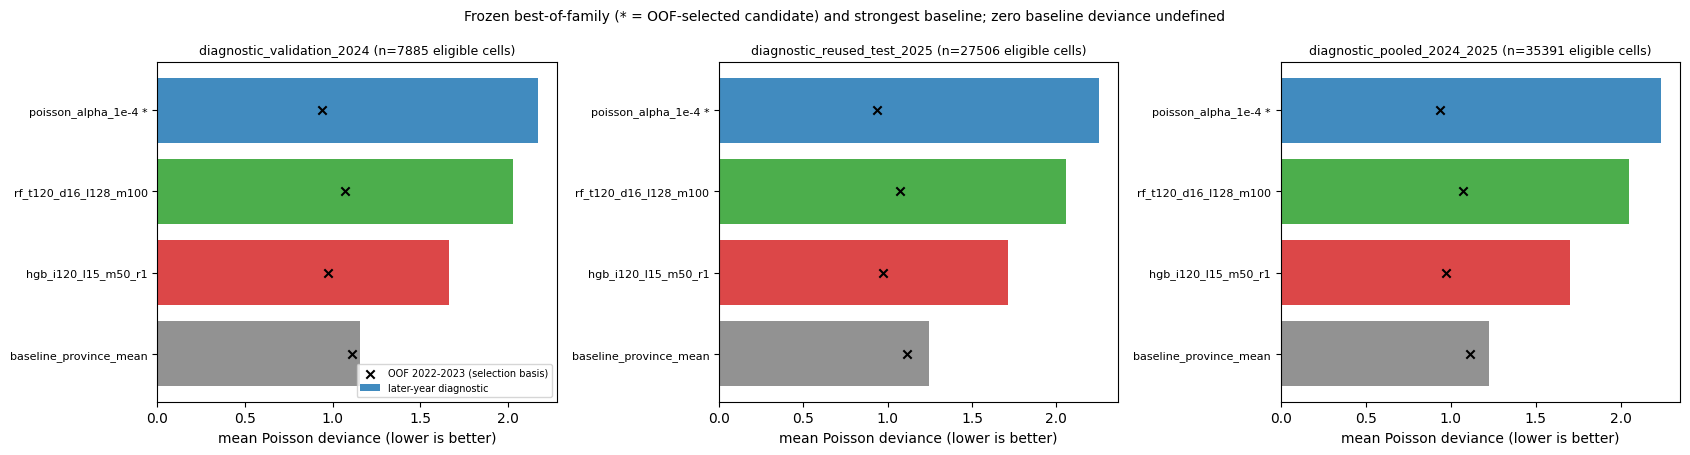

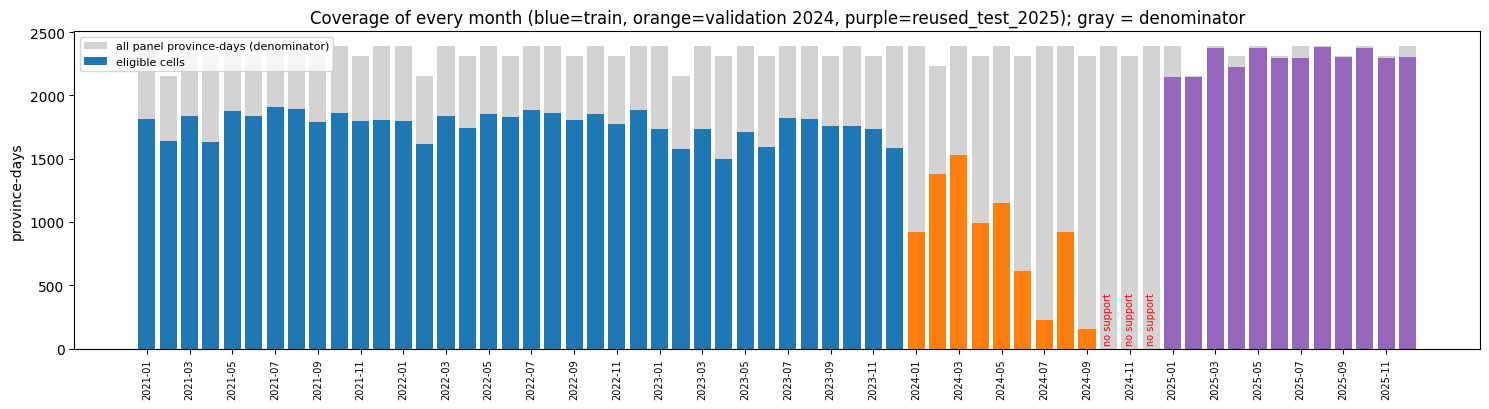

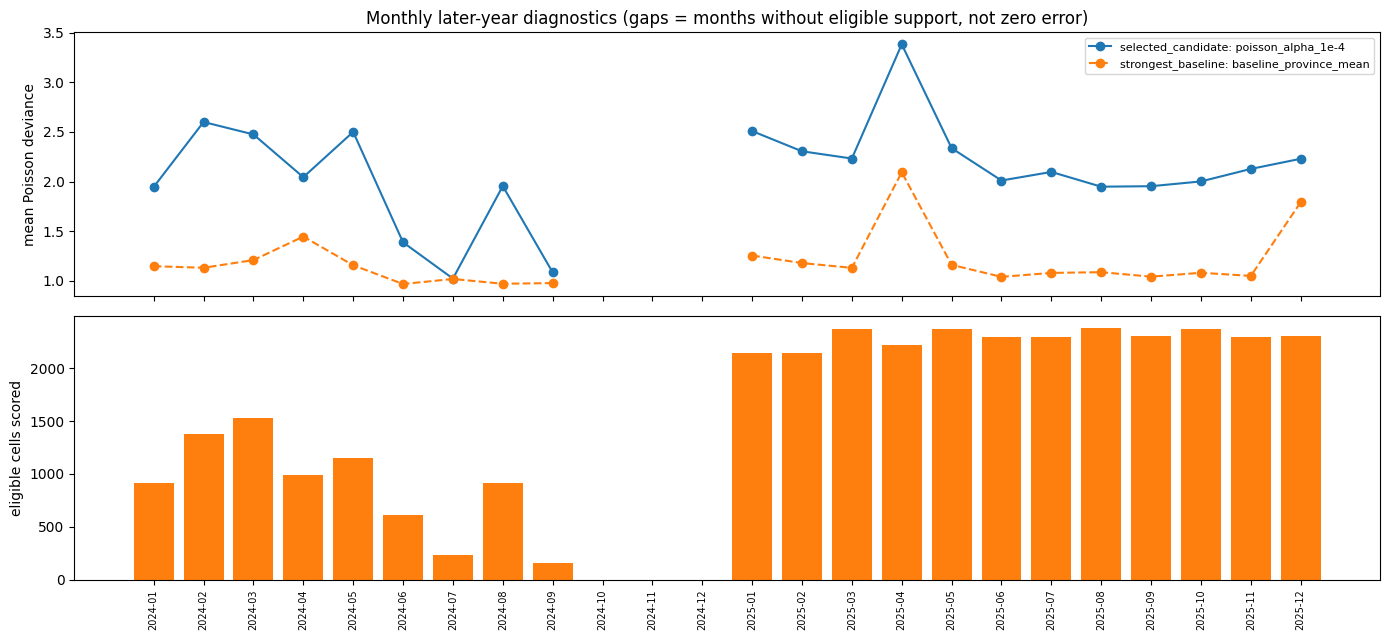

In [10]:
fam_color = {'baseline': 'tab:gray', 'poisson': 'tab:blue', 'random_forest': 'tab:green', 'hist_gradient_boosting': 'tab:red'}
plot_main = MAIN[MAIN['mean_poisson_deviance'].notna()]
fig, axes = plt.subplots(1, len(DIAG_SCOPES), figsize=(17, 4.6))
for ax, scope in zip(axes, DIAG_SCOPES):
    sub = plot_main[plot_main['evaluation_scope'] == scope]
    ys = np.arange(len(sub))
    ax.barh(ys, sub['mean_poisson_deviance'].astype(float), color=sub['family'].map(fam_color), alpha=0.85, label='later-year diagnostic')
    ax.scatter(sub['oof_mean_poisson_deviance'].astype(float), ys, color='black', marker='x', zorder=3, label='OOF 2022-2023 (selection basis)')
    ax.set_yticks(ys)
    ax.set_yticklabels([s + (' *' if sel else '') for s, sel in zip(sub['spec_id'], sub['is_selected_candidate'])], fontsize=8)
    ax.invert_yaxis()
    ax.set_title('%s (n=%d eligible cells)' % (scope, int(sub['n_rows'].iloc[0]) if len(sub) else 0), fontsize=9)
    ax.set_xlabel('mean Poisson deviance (lower is better)')
axes[0].legend(fontsize=7, loc='lower right')
fig.suptitle('Frozen best-of-family (* = OOF-selected candidate) and strongest baseline; zero baseline deviance undefined', fontsize=10)
fig.tight_layout()
fig.savefig(DIAG / 'diagnostic_main_deviance.png', dpi=110)
plt.show()

fig, ax = plt.subplots(figsize=(15, 4.2))
xs = np.arange(len(COVERAGE))
ax.bar(xs, COVERAGE['panel_rows'], color='lightgray', label='all panel province-days (denominator)')
ax.bar(xs, COVERAGE['eligible_rows'], color=COVERAGE['split'].map({'train': 'tab:blue', 'validation': 'tab:orange', 'reused_test_2025': 'tab:purple'}),
       label='eligible cells')
for i in COVERAGE.index[COVERAGE['eligible_rows'] == 0]:
    ax.text(i, 30, 'no support', rotation=90, fontsize=7, ha='center', va='bottom', color='red')
ax.set_xticks(xs[::2])
ax.set_xticklabels(COVERAGE['month'].iloc[::2], rotation=90, fontsize=7)
ax.set_ylabel('province-days')
ax.set_title('Coverage of every month (blue=train, orange=validation 2024, purple=reused_test_2025); gray = denominator')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(DIAG / 'coverage_by_split_month.png', dpi=110)
plt.show()

later_cov = COVERAGE[COVERAGE['split'].isin(DIAGNOSTIC_SPLITS)].reset_index(drop=True)
fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)
xs = np.arange(len(later_cov))
for label, style in (('selected_candidate', '-'), ('strongest_baseline', '--')):
    axes[0].plot(xs, pd.to_numeric(later_cov[label + '__mean_poisson_deviance']), marker='o', linestyle=style,
                 label=label + ': ' + later_cov[label + '_spec_id'].iloc[0])
axes[0].set_ylabel('mean Poisson deviance')
axes[0].set_title('Monthly later-year diagnostics (gaps = months without eligible support, not zero error)')
axes[0].legend(fontsize=8)
axes[1].bar(xs, later_cov['eligible_rows'], color='tab:orange')
axes[1].set_ylabel('eligible cells scored')
axes[1].set_xticks(xs)
axes[1].set_xticklabels(later_cov['month'], rotation=90, fontsize=7)
fig.tight_layout()
fig.savefig(DIAG / 'diagnostic_monthly_deviance.png', dpi=110)
plt.show()

## 6. ตรวจซ้ำหลังให้คะแนน, Manifest และสัญญาสำหรับ Notebook 08

ก่อนเขียนสถานะ `ok`: ตรวจ `selection_lock.json` อีกครั้ง (ไบต์ไฟล์ + `decision_sha256` + `choice_sha256`), ตรวจว่าไฟล์/bundle/manifest ของ 06 ทุกไฟล์ hash ไม่เปลี่ยน และไฟล์ prediction ไม่ถูกแก้หลังคำนวณ

`diagnostic_manifest.json` บันทึก hash ของทุกไฟล์ผลลัพธ์ วิธีเปรียบเทียบข้ามการรันซ้ำ (`exact` / `numeric_tolerance` / `none`), hash ของอินพุตและ source, เวอร์ชันแพ็กเกจ, provenance ของ runner และ `next_stage_contract` สำหรับ 08

In [11]:
LOCK_FILE_SHA_AFTER = assert_lock_unchanged(LOCK_PATH, SEL06['decision_sha256'], SEL06['choice_sha256'], LOCK_FILE_SHA_BEFORE)
LOCK_AFTER = verify_selection_lock(LOCK_PATH, SEL06['decision_sha256'], SEL06['choice_sha256'])
assert canonical_json(LOCK_AFTER['choice']) == canonical_json(CHOICE), 'frozen choice changed during 07'
UPSTREAM_AFTER = upstream_file_hashes(OUT, ART_MAN)
changed = sorted(k for k in set(UPSTREAM_BEFORE) | set(UPSTREAM_AFTER) if UPSTREAM_BEFORE.get(k) != UPSTREAM_AFTER.get(k))
assert not changed, 'notebook-06 artifacts changed during 07: ' + ', '.join(changed)
assert sha256_file(PRED_PATH) == PRED_SHA, 'diagnostic predictions changed after scoring'

def rel(p):
    return Path(p).relative_to(OUT).as_posix()

OUTPUT_FILES = {
    'exact': [DIAG / 'diagnostic_support_by_split.csv'],
    'numeric_tolerance': [PRED_PATH, DIAG / 'diagnostic_metrics_long.csv', DIAG / 'diagnostic_monthly_metrics.csv', DIAG / 'coverage_by_split_month.csv',
                          DIAG / 'diagnostic_main_results.csv', DIAG / 'diagnostic_all_configs.csv', DIAG / 'later_year_rank_comparison.csv',
                          DIAG / 'train_in_sample_metrics.csv'],
    'none': [DIAG / 'metric_recomputation_check.csv', DIAG / 'runtime_by_spec.csv', DIAG / 'diagnostic_main_deviance.png',
             DIAG / 'coverage_by_split_month.png', DIAG / 'diagnostic_monthly_deviance.png'],
}
files = [{'path': rel(p), 'sha256': sha256_file(p), 'cross_run_comparison': kind} for kind, ps in OUTPUT_FILES.items() for p in ps]
assert not {f['path'] for f in files} & set(UPSTREAM_BEFORE), '07 must not overwrite notebook-06 artifacts'
OOF_REL = next(f['path'] for f in ART_MAN['files'] if f['path'].endswith('oof_predictions.csv'))
NEXT_STAGE_08 = {
    'require': [rel(DIAG_MAN_PATH) + ' status == ok and every files[].sha256 matches the file on disk',
                'upstream_06 hashes still match experiment_manifest.json, model_artifact_manifest.json and selection_lock.json'],
    'load': ['exec the # FUNCTIONS cell of backend/notebooks/06_baseline_candidate_models.ipynb only if its sha256 == source.verified_06.functions_cell_sha256',
             'then (optional) exec the # FUNCTIONS cell of backend/notebooks/07_evaluation_experiment_results.ipynb only if its sha256 == source.functions_cell_07_sha256'],
    'verify': ['verify_selection_lock(selection_lock.json, decision_sha256, choice_sha256) and its file sha256 before and after analysis',
               'frozen_choice is the only source of selected candidate / best per family / strongest baseline / recommended reference'],
    'predictions': {'path': rel(PRED_PATH), 'sha256': PRED_SHA, 'rows': int(len(SAVED)), 'columns': list(SAVED.columns),
                    'key': ['province', 'target_date'], 'split_column': 'split', 'scope_column': 'evaluation_scope', 'scope_by_split': SCOPE_BY_SPLIT,
                    'target': TARGET, 'prediction_columns': ['pred__' + s['id'] for s in SPECS], 'eligible_cells_only': True,
                    'row_order': 'split (validation, reused_test_2025), target_date, province',
                    'note': 'raw predictions; deviance uses max(pred, deviance_floor); zero baseline deviance is undefined (null)'},
    'oof_predictions': {'path': OOF_REL, 'sha256': ART_MAN['oof_predictions_sha256'], 'scope': OOF_SCOPE},
    'tables': {k: rel(DIAG / (k + '.csv')) for k in ('diagnostic_metrics_long', 'diagnostic_monthly_metrics', 'coverage_by_split_month',
                                                    'diagnostic_main_results', 'diagnostic_all_configs', 'later_year_rank_comparison',
                                                    'diagnostic_support_by_split', 'train_in_sample_metrics')},
    'deviance_floor': FLOOR, 'metric_keys': METRIC_KEYS, 'support_keys': SUPPORT_KEYS, 'scopes': DIAG_SCOPES,
    'forbidden': ['refit, tune or calibrate on 2024/2025', 'change selected_candidate / recommended_reference from later-year scores',
                  'use 2026 as labels', 'present eligible-cell scores as full-year, whole-country or route accuracy'],
}
write_json(DIAG_MAN_PATH, {
    'producer': PRODUCER_07, 'format': DIAG_FORMAT, 'status': 'ok', 'experiment_id': XCFG['experiment_id'],
    'research_mode': XCFG['research_mode'], 'production_enabled': False,
    'data_foundation_final_model_readiness': DATA_REPORT['final_model_readiness'], 'caveats': CAVEATS + DIAG_CAVEATS,
    'later_years_used_for_selection': False, 'refit_or_tuning_performed': False, 'calibration_performed': False,
    'diagnostic_2026_labels_used': False, 'frozen_choice': CHOICE,
    'decision_sha256': LOCK['decision_sha256'], 'choice_sha256': LOCK['choice_sha256'],
    'selection_lock_check': {'file_sha256_before': LOCK_FILE_SHA_BEFORE, 'file_sha256_after': LOCK_FILE_SHA_AFTER, 'unchanged': True,
                             'hashes_verified_before_and_after_scoring': True},
    'upstream_06': {'experiment_manifest_sha256': UPSTREAM_AFTER[rel(EXP_MAN_PATH)], 'model_artifact_manifest_sha256': ART_MAN_FILE_SHA,
                    'selection_lock_file_sha256': LOCK_FILE_SHA_BEFORE, 'oof_predictions_sha256': ART_MAN['oof_predictions_sha256'],
                    'bundle_sha256': {b['spec_id']: b['bundle_sha256'] for b in ART_MAN['bundles']},
                    'n_files_hashed_before_and_after': len(UPSTREAM_AFTER), 'all_unchanged_after_scoring': True},
    'contract': CONTRACT_NOW,
    'source': {'verified_06': SOURCE_NOW, 'notebook_07_semantic_sha256': notebook_semantic_sha256(NB07_PATH),
               'functions_cell_07_sha256': sha256_bytes(functions_cell_source(NB07_PATH).encode('utf-8'))},
    'runner_provenance': RUNNER_PROVENANCE, 'package_versions': package_versions(), 'package_versions_recorded_by_06': EXP_MAN.get('package_versions'),
    'eligibility': records(SPLIT_SUPPORT), 'support_warnings': SUPPORT_TEXT,
    'metric_recomputation': {'tolerance_scaled': METRIC_RECOMPUTE_TOL, 'max_scaled_abs_diff': RECOMP['max_scaled_abs_diff'].max(),
                             'saved_vs_in_memory_max_abs_diff': SAVED_VS_MEMORY, 'prediction_csv_roundtrip_max_abs_diff': ROUNDTRIP_MAX,
                             'oracle': 'scikit-learn mean_absolute_error / mean_squared_error / mean_poisson_deviance + numpy sums'},
    'main_results': records(MAIN.drop(columns=['support_warning'])), 'later_year_rank_comparison': records(RANKS),
    'files': files, 'next_stage_contract': NEXT_STAGE_08,
    'run_info_nondeterministic': {'started_utc': STARTED_UTC, 'finished_utc': dt.datetime.now(dt.timezone.utc).isoformat(),
                                  'data_root': str(DATA_ROOT), 'output_root': str(OUT), 'python_executable': sys.executable},
})
json.loads(DIAG_MAN_PATH.read_text('utf-8'))  # strict finite JSON (write_json uses allow_nan=False)
print('selection_lock.json unchanged:', LOCK_FILE_SHA_AFTER == LOCK_FILE_SHA_BEFORE, '| 06 artifacts unchanged:', len(UPSTREAM_AFTER), 'files')
print('wrote', DIAG_MAN_PATH, '(status ok)')
pd.DataFrame(files)

selection_lock.json unchanged: True | 06 artifacts unchanged: 27 files
wrote /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend/reports/models/diagnostics/diagnostic_manifest.json (status ok)


,path,sha256,cross_run_comparison
0,reports/models/diagnostics/diagnostic_support_...,28fa179f75a14749198a9f0dad75ad66716b23e9da8284...,exact
1,data/model/diagnostic_predictions.csv,6f5138386a5d0c88c4c1a5008abefa655ba3c9e0bce226...,numeric_tolerance
2,reports/models/diagnostics/diagnostic_metrics_...,c22bccaeb700466f31e2c4d5d0fb9608339802474b0582...,numeric_tolerance
3,reports/models/diagnostics/diagnostic_monthly_...,fa275f737751606043fc78943b4bcf55d1dc9c8db05ec7...,numeric_tolerance
4,reports/models/diagnostics/coverage_by_split_m...,27d7de701eff18ef4d6b3e7930b76cbb201844330d9369...,numeric_tolerance
5,reports/models/diagnostics/diagnostic_main_res...,0face8b254eab2a23235713d563b172d84f895a394a7ac...,numeric_tolerance
6,reports/models/diagnostics/diagnostic_all_conf...,3ba90ed2541727ca9c83c3847e9f668a73a44e66d5339e...,numeric_tolerance
7,reports/models/diagnostics/later_year_rank_com...,acd495921292fc09d906391b7250f09105ce86e812985a...,numeric_tolerance
8,reports/models/diagnostics/train_in_sample_met...,c12d7c6f7d6846ea5b241474aa6407467c3720b3452c72...,numeric_tolerance
9,reports/models/diagnostics/metric_recomputatio...,e0fc14607dc17659282c8d2ce4ae0bd72531ae3b76b5fa...,none


In [12]:
def fmt(x):
    return 'null' if pd.isna(x) else '%.4f' % float(x)

print('ACTUAL LATER-YEAR DIAGNOSTICS (eligible cells only; frozen OOF choice; research mode, production disabled)')
print('frozen selected candidate:', CHOICE['selected_candidate'], '| strongest baseline:', CHOICE['best_baseline'],
      '| recommended reference from the OOF gate:', CHOICE['recommended_reference'], '(' + CHOICE['recommended_reference_type'] + ')')
rk = RANKS.set_index('evaluation_scope')
for scope in DIAG_SCOPES:
    print('-' * 110)
    print(scope)
    print('  SUPPORT:', SUPPORT_TEXT[scope])
    for r in MAIN[MAIN['evaluation_scope'] == scope].to_dict('records'):
        print('  %-38s %-28s deviance=%s MAE=%s RMSE=%s bias=%s | OOF deviance=%s' % (
            r['role'] + (' [selected]' if r['is_selected_candidate'] else ''), r['spec_id'], fmt(r['mean_poisson_deviance']), fmt(r['mae']),
            fmt(r['rmse']), fmt(r['bias']), fmt(r['oof_mean_poisson_deviance'])))
    x = rk.loc[scope]
    print('  selected candidate beats strongest baseline on deviance:', x['selected_candidate_beats_strongest_baseline'],
          '| family bests beating it:', x['n_family_bests_beating_strongest_baseline'], 'of', len(FAMILY_ORDER))
    print('  lowest later-year deviance among family bests:', x['later_lowest_deviance_family_best'],
          '| differs from frozen pick:', x['family_best_rank_differs'], '(reported only; frozen choice unchanged)')
print('-' * 110)
print('NOTE: selection and reference stay as locked from 2022-2023 OOF; these scores are retrospective, selection-biased diagnostics.')

ACTUAL LATER-YEAR DIAGNOSTICS (eligible cells only; frozen OOF choice; research mode, production disabled)
frozen selected candidate: poisson_alpha_1e-4 | strongest baseline: baseline_province_mean | recommended reference from the OOF gate: poisson_alpha_1e-4 (candidate)
--------------------------------------------------------------------------------------------------------------
diagnostic_validation_2024
  SUPPORT: eligible cells only: 7885 of 28182 province-days (28.0%) on 103 dates; months without eligible support: 2024-10, 2024-11, 2024-12; selection-biased by training_eligible; not full-year, whole-country or route accuracy
  best_of_family:poisson [selected]      poisson_alpha_1e-4           deviance=2.1700 MAE=0.7252 RMSE=1.2374 bias=-0.3553 | OOF deviance=0.9371
  best_of_family:random_forest           rf_t120_d16_l128_m100        deviance=2.0300 MAE=0.7645 RMSE=1.2393 bias=-0.3372 | OOF deviance=1.0713
  best_of_family:hist_gradient_boosting  hgb_i120_l15_m50_r1          devi

## สรุปและข้อจำกัด (อ่านคู่กับผลจริงด้านบน)

- ตัวเลขทั้งหมดมาจากการรันจริงในเซลล์ด้านบน คำนวณจาก `data/model/diagnostic_predictions.csv` และคำนวณซ้ำแบบอิสระแล้ว ถ้า notebook ไม่มี output แปลว่ายังไม่ได้รัน
- ตัวที่ถูกเลือก (selected candidate), ตัวดีที่สุดของแต่ละตระกูล, Baseline ที่แข็งที่สุด และ recommended reference มาจาก `selection_lock.json` ของ 06 (OOF 2022–2023) เท่านั้น ถ้าคะแนนปีหลังจัดอันดับต่างไป จะรายงานเป็นข้อค้นพบ/ข้อจำกัด **ไม่ใช่** การเลือกผู้ชนะใหม่
- คะแนนอธิบายเฉพาะเซลล์ eligible (selection bias จาก `training_eligible`) ดูคำเตือน support ข้างคะแนนทุกแถว เดือนที่ไม่มีเซลล์ eligible มีคะแนน null ไม่ใช่ศูนย์ ไม่มีการอ้างความแม่นยำทั้งปี ทั้งประเทศ หรือรายสายทาง
- ปี 2025 เคยถูกดูแล้ว ไม่มี test อิสระ; ไม่มีการใช้ป้ายกำกับปี 2026; ไม่มีการ refit/tune/calibrate
- Error analysis รายเดือน/จังหวัด/วันในสัปดาห์/ช่วงจำนวน, calibration-style bins, cohort shift และ model card เป็นงานของ Notebook 08 ซึ่งใช้ `next_stage_contract` ใน `reports/models/diagnostics/diagnostic_manifest.json`
- ความพร้อมของโมเดลจริง: **BLOCKED**; `production_enabled = False`